Central question: Where can I identify significant differences in seasonal and tidal variability across three Mid-Atlantic tidal creeks?

In [64]:
import pandas as pd # helps us import files
import numpy as np # math
import matplotlib.pyplot as plt # makes figures 
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import seaborn as sns # provides clean default styles
import cartopy as cp # handles map projections
import cartopy.crs as ccrs # handles map projections 
import cartopy.feature as cfeature # adds map features like basemaps, coastlines, rivers
import cartopy.io.img_tiles as cimgt

In [67]:
# import data
infile_flsp = r'C:\Users\joann\FLSP-GCREW-TASK\DATA\raw\FLSP_export.csv'
infile_gcrew = r'C:\Users\joann\FLSP-GCREW-TASK\DATA\raw\GCREW_export.csv'
infile_task = r'C:\Users\joann\FLSP-GCREW-TASK\DATA\raw\TASK_export.csv'

data_flsp = pd.read_csv(infile_flsp, sep=',')
data_gcrew = pd.read_csv(infile_gcrew, sep=',')
data_task = pd.read_csv(infile_task, sep=',')

# see columns
print("--- FLSP ---") 
print(data_flsp.columns) 

print("\n--- GCREW ---") 
print(data_gcrew.columns) 

print("\n--- TASK ---")
print(data_task.columns) 

import os
EXPORT_DIR = r"C:\Users\joann\FLSP-GCREW-TASK\EXPORTS"  # <-- paste your copied folder path here
os.makedirs(EXPORT_DIR, exist_ok=True)

def save_fig(fig, name):
    out_path = os.path.join(EXPORT_DIR, f"{name}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print("Saved to:", out_path)

--- FLSP ---
Index(['Sample_ID', 'Season', 'Tidal_Cycle', 'Sample_Datetime', 'Time_local',
       'Sample_Type', 'Ra223_dpm100L', 'Ra223_err', 'Ra224_dpm100L',
       'Ra224_err', 'Ra226_dpm100L', 'Ra226_err', 'Ra228_dpmL', 'Ra228_err',
       'Ra224_223', 'Ra228_226', 'Ra224_228', 'Ra224_226', 'Ra224_Si',
       'Ra226_Si', 'Salinity', 'Depth_m', 'Temp_C', 'pH', 'ORP_mV', 'DO_sat',
       'DO_mg_L', 'SpcCon _uS_cm', 'FlowRate_m3_s', 'NOx', 'PO4', 'NH3',
       'Si_uM', 'fCO2_uatm', 'CH4_nM', 'DIC_umolL', 'DOC_umolL', 'TA_mmolkg'],
      dtype='str')

--- GCREW ---
Index(['Sample_ID', 'Sample_Type', 'Tidal_Cycle', 'Sample_Datetime',
       'volume_L', 'delta_volume_L', 'Ra223_dpm100L', 'Ra223_err',
       'Ra224_dpm100L', 'Ra224_err', 'Ra226_dpm100L', 'Ra226_err',
       'Ra228_dpm100L', 'Ra228_err', 'Ra224_223', 'Ra228_226', 'Ra224_228',
       'Ra224_226', 'Salinity', 'Time_local', 'Season', 'Depth_m', 'Temp_C',
       'DO_mg_L', 'Chlorophyll_ug_L', 'pH', 'amb_t_c', 'CO2d_ppm',
     

Spatial & Temporal Coverage:

First Landing State Park (FLSP) ghost forest: Located in Virginia Beach, VA (-75.995833, -76.009722, 36.886111, 36.888888); 2 campaigns in summer '26 (spring vs neap) and 2 anticipated winter '27 (12-hr time series)

Smithsonian Environmental Research Center (GCREW): Located in Edgewater, MD (-76.545833, -76.551944, 38.873055, 38.875277); 2 campaigns in summer '23 (spring vs neap) and 2 campaigns in winter '24 (12-hr time series)

Taskinas Creek (TASK): Located in York River State Park, VA (-76.714166, -76.716388, 37.413333, 37.415555); 6 campaigns total (fall '23, spring '24, summer '24, fall '24, winter '25, spring '25, fall '26)

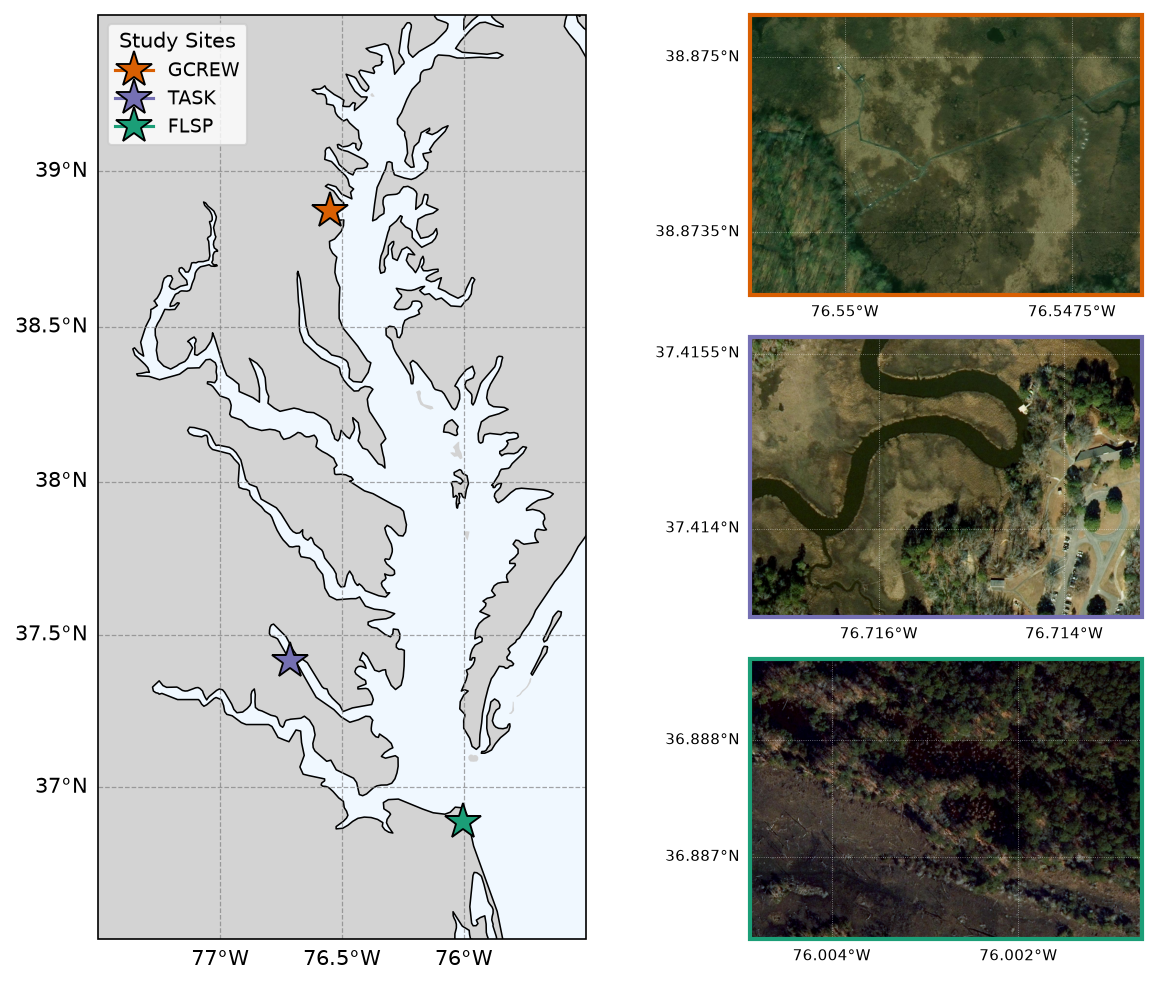

Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\map.png


In [68]:
# 1. Site center coordinates (lon, lat) and colors
sites = {
    'GCREW': {
        'center': (-76.548889, 38.874166),
        'color': '#d95f02',  # orange
    },
    'TASK': {
        'center': (-76.715277, 37.414444),
        'color': '#7570b3',  # purple
    },
    'FLSP': {
        'center': (-76.002778, 36.887500),
        'color': '#1b9e77',  # teal
    }
}

# 2. Set up figure and tight GridSpec layout
fig = plt.figure(figsize=(10, 8), dpi=150)
gs = gridspec.GridSpec(3, 2, width_ratios=[1.35, 1], wspace=0.08, hspace=0.15)

# --- LEFT PANEL: Chesapeake Bay Regional Map ---
ax_bay = fig.add_subplot(gs[:, 0], projection=ccrs.Mercator())
ax_bay.set_extent([-77.5, -75.5, 36.5, 39.5], crs=ccrs.PlateCarree())

ax_bay.add_feature(cfeature.LAND, facecolor='lightgrey', zorder=1)
ax_bay.set_facecolor('aliceblue')  # clean water fill without extra downloads
ax_bay.coastlines(linewidth=0.75, color='black', zorder=2)

# Plot larger colored stars for each site
for name, info in sites.items():
    lon, lat = info['center']
    ax_bay.plot(
        lon, lat,
        marker='*', markersize=18, color=info['color'],
        markeredgecolor='black', markeredgewidth=0.9,
        transform=ccrs.PlateCarree(), label=name, zorder=5
    )

ax_bay.legend(loc='upper left', frameon=True, title='Study Sites', fontsize=9)

gl = ax_bay.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=0.6, color='gray', linestyle='--', alpha=0.7)
gl.top_labels = False
gl.right_labels = False
gl.ylocator = mticker.FixedLocator([37.0, 37.5, 38.0, 38.5, 39.0])
gl.xlocator = mticker.FixedLocator([-77.5, -77.0, -76.5, -76.0, -75.5])

# --- RIGHT PANELS: Uniform, Close-Up Site Views (North to South) ---
esri_imagery = cimgt.GoogleTiles(
    url='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'
)

panel_order = ['GCREW', 'TASK', 'FLSP']
lat_span = 0.0012  # ~130m north/south from center (try 0.0008 for even tighter)

for row_idx, site_key in enumerate(panel_order):
    info = sites[site_key]
    lon, lat = info['center']
    
    # Scale longitude span by cos(lat) so all 3 boxes cover identical physical dimensions
    lon_span = (lat_span * 1.4) / np.cos(np.radians(lat))
    
    ax_site = fig.add_subplot(gs[row_idx, 1], projection=esri_imagery.crs)
    ax_site.set_extent([lon - lon_span, lon + lon_span, lat - lat_span, lat + lat_span],
                       crs=ccrs.PlateCarree())
    ax_site.set_adjustable('box')  # forces all 3 subplots to share exact visual dimensions
    
    # Zoom 17 gives sharp, close-up creek imagery
    ax_site.add_image(esri_imagery, 19)  # max sharp aerial resolution (~0.3m/pixel)
    
    # Thin colored border matching the site star on the main map
    for spine in ax_site.spines.values():
        spine.set_edgecolor(info['color'])
        spine.set_linewidth(2.0)
    
    gl_sub = ax_site.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                               linewidth=0.4, color='white', linestyle=':', alpha=0.5)
    gl_sub.top_labels = False
    gl_sub.right_labels = False
    gl_sub.xlabel_style = {'size': 7}
    gl_sub.ylabel_style = {'size': 7}
    gl_sub.xlocator = mticker.MaxNLocator(nbins=2)
    gl_sub.ylocator = mticker.MaxNLocator(nbins=2)

plt.show()

from PIL import ImageEnhance

class BrightEsriTiles(cimgt.GoogleTiles):
    def __init__(self, brightness=1.35, contrast=1.15):
        super().__init__(
            url='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'
        )
        self.brightness = brightness
        self.contrast = contrast

    def get_image(self, tile):
        img, extent, origin = super().get_image(tile)
        img = ImageEnhance.Brightness(img).enhance(self.brightness)
        img = ImageEnhance.Contrast(img).enhance(self.contrast)
        return img, extent, origin

esri_imagery = BrightEsriTiles(brightness=1.35, contrast=1.15)

save_fig(fig, "map")
plt.show()

This is a rough draft of my map. I want to add different symbols or colors to differentiate PW/SW/GW sampling stations within each of my three sites. I will also add in panel letters A, B, C, D using code or canva. Do we think the coorindates in the side panels are necessary if the coordinates in panel A give an idea of lat/long?

To start, I will analyze seasonal and tidal variability in the GCREW dataset.

In [6]:
# inspect unique values in Season and Tidal_Cycle columns
print("=== Unique Seasons in GCREW ===")
print(data_gcrew['Season'].unique()) 

print("\n=== Unique Tidal Cycles in GCREW ===") 
print(data_gcrew['Tidal_Cycle'].unique()) 

# cross-tabulate sample counts across Season, Tidal_Cycle, and Sample_Type
print("\n=== Sample Counts by Season, Tidal Cycle, and Sample Type ===") 
gcrew_counts = pd.crosstab(
    index=[data_gcrew['Season'], data_gcrew['Tidal_Cycle']], # row categories
    columns=data_gcrew['Sample_Type'] # column categories
) 

display(gcrew_counts) 

=== Unique Seasons in GCREW ===
<StringArray>
['Summer 2023', 'Winter 2024']
Length: 2, dtype: str

=== Unique Tidal Cycles in GCREW ===
<StringArray>
['neap', 'spring']
Length: 2, dtype: str

=== Sample Counts by Season, Tidal Cycle, and Sample Type ===


Sample_Type              GW  PW  SW
Season      Tidal_Cycle            
Summer 2023 neap          0   6  13
            spring        2   6  13
Winter 2024 neap          0   5  12
            spring        4   4  13

There were 2 GW and 12 PW samples collected in summer and 4 GW and 9 PW samplescollected in winter. There were 13 SW samples collected during each time series, with the exception of only 12 SW samples collected during the spring tide in the winter. I need to keep in mind that we are only interested in comparing SW when analyzing tidal variability. PW and GW respond more heavily to seasonal hydraulic gradients than tides.

Task was destroyed but it is pending!
task: <Task pending name='Task-758' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\joann\anaconda3\envs\MYENV\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-759' coro=<Kernel.shell_main() running at C:\Users\joann\anaconda3\envs\MYENV\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\joann\anaconda3\envs\MYENV\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\joann\anaconda3\envs\MYENV\Lib\site-packages\matplotlib\font_manager.py:1323: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  @staticmethod
Task was destroyed but it is pending!
task: <Task pending name='Task-759' coro=<Kernel.shell_main() running at C:\Users\joann\anaconda3\envs\MYENV\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


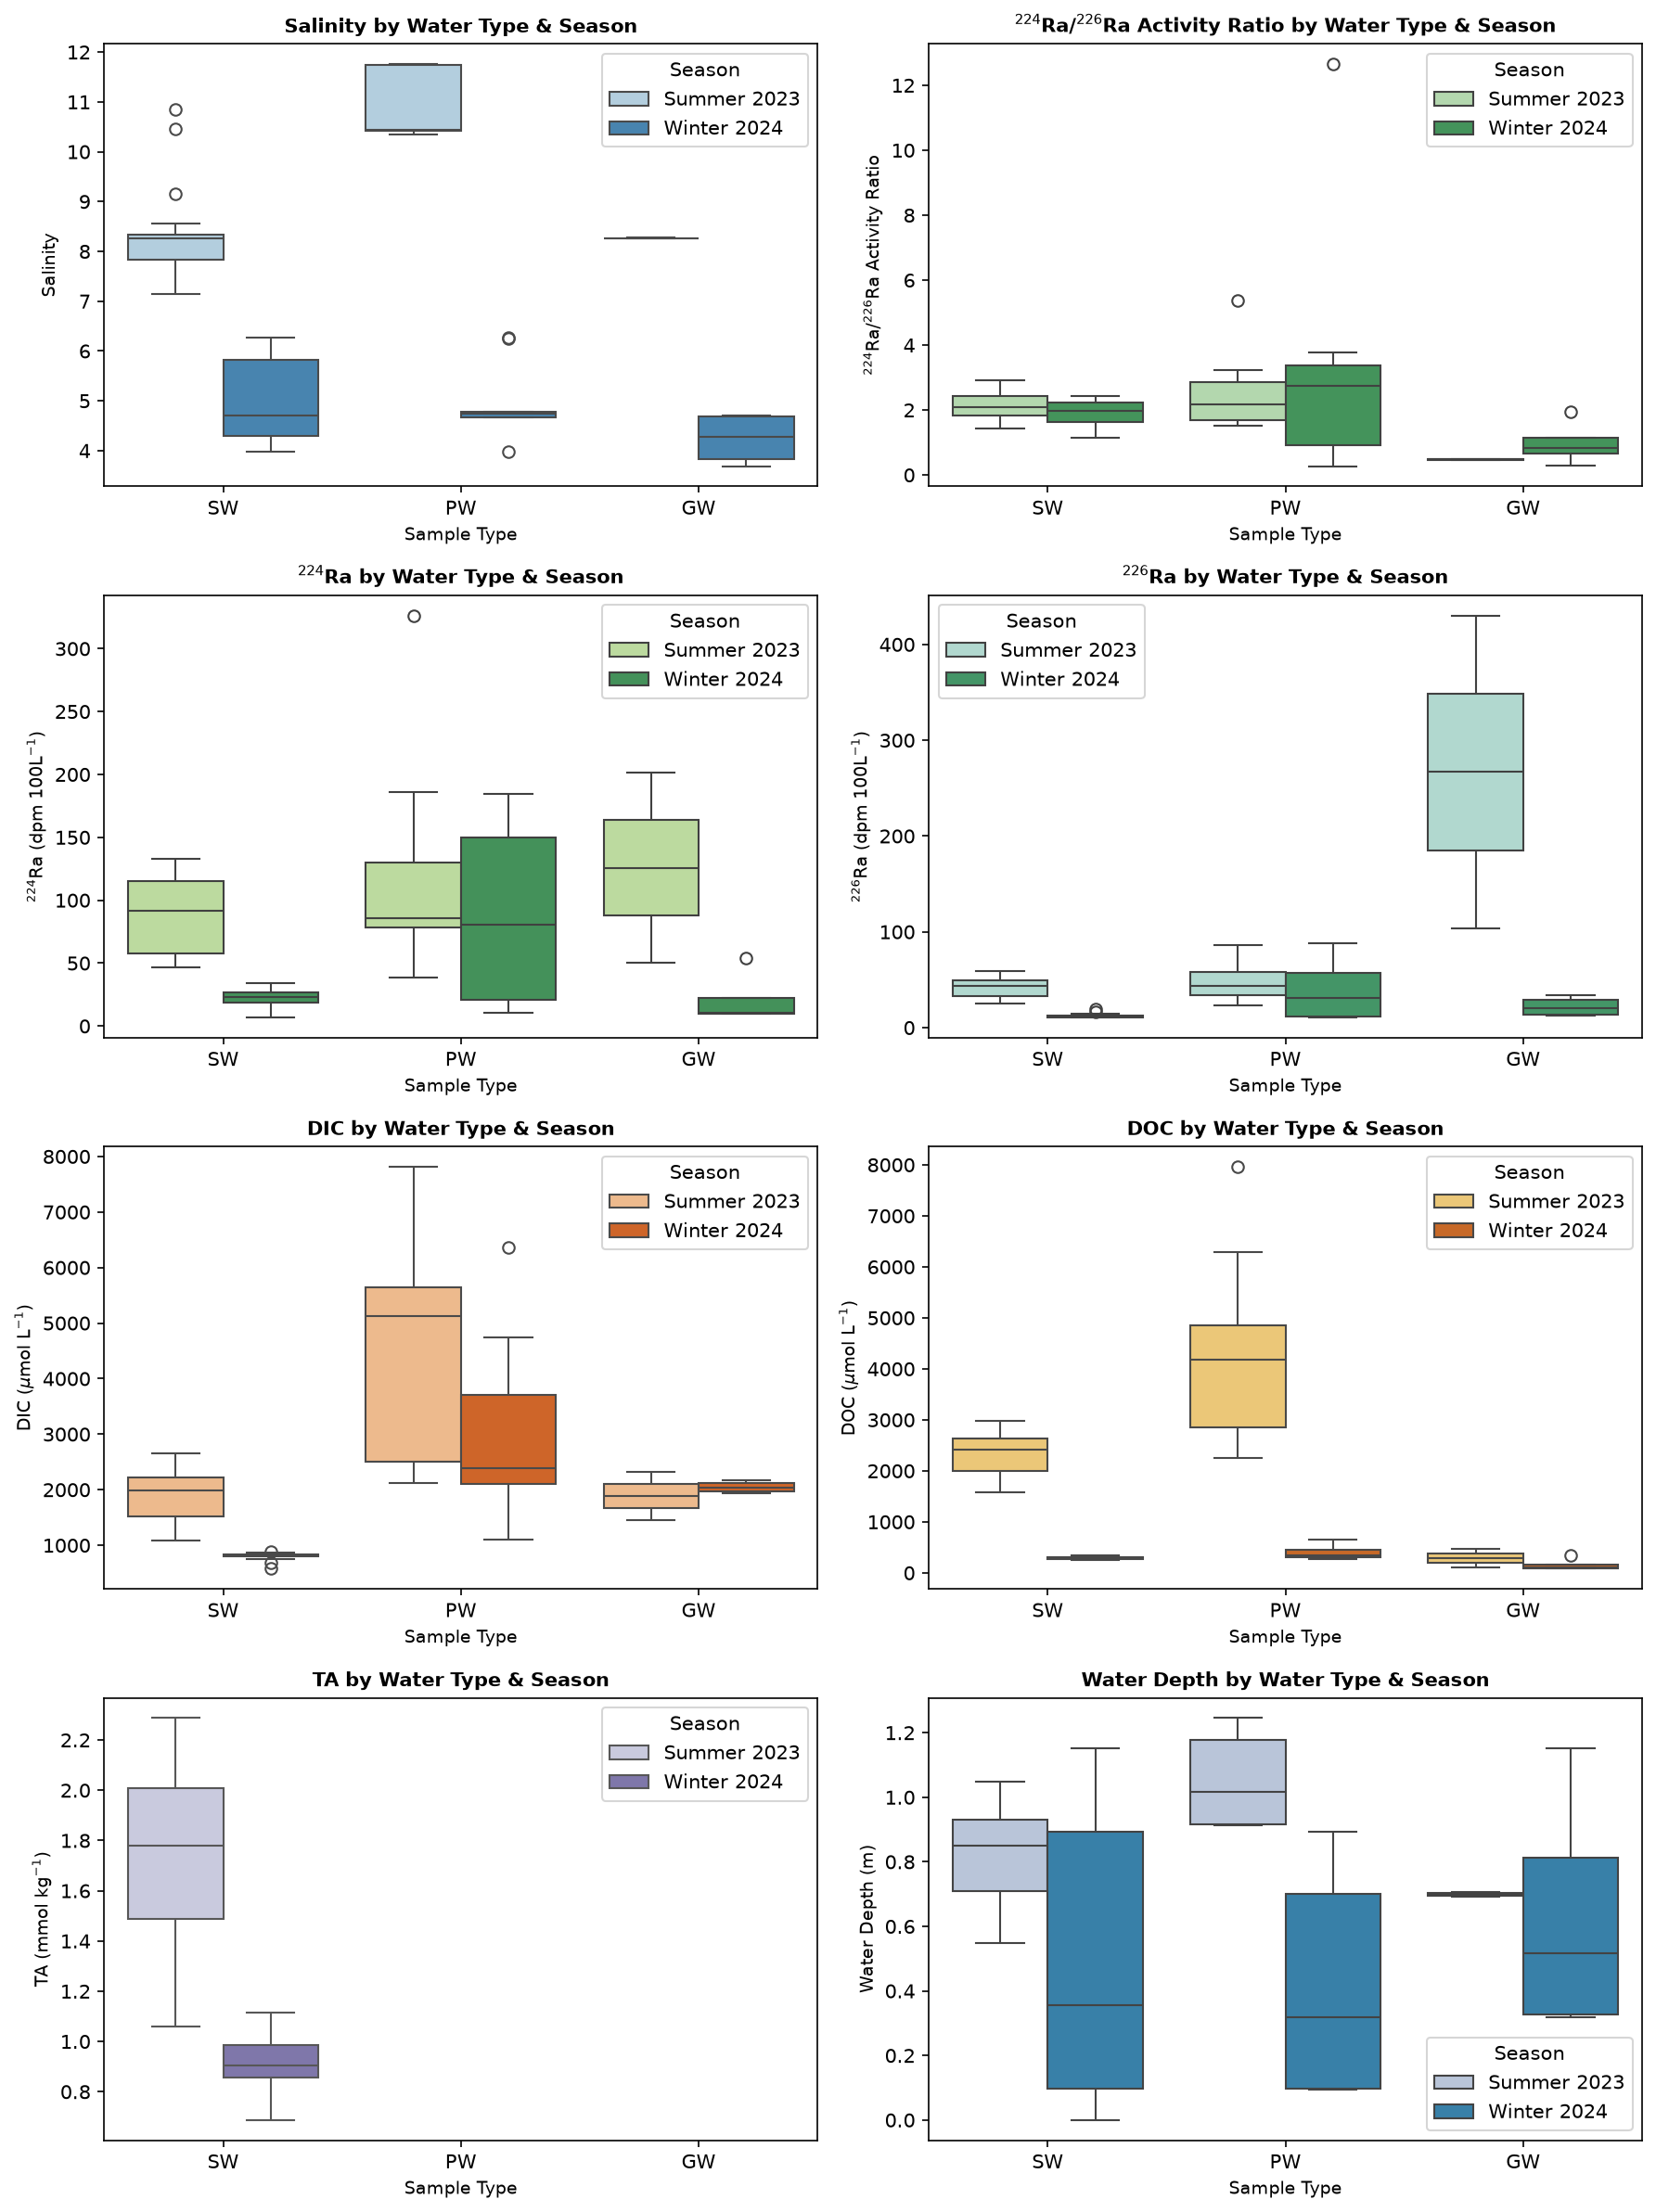

Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\GCREW-watertype-season-boxplots.png


<Figure size 640x480 with 0 Axes>

In [69]:
# create 4x2 grid of boxplots comparing Season across Sample_Type
fig, axes = plt.subplots(4, 2, figsize=(12, 16), dpi=150)

# plot 1: Salinity (Row 0, Col 0)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='Salinity', hue='Season', ax=axes[0, 0], palette='Blues')
axes[0, 0].set_title('Salinity by Water Type & Season', fontsize=10, fontweight='bold')
axes[0, 0].set_xlabel('Sample Type', fontsize=9)
axes[0, 0].set_ylabel('Salinity', fontsize=9)

# plot 2: Ra-224 / Ra-226 ratio (Row 0, Col 1)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='Ra224_226', hue='Season', ax=axes[0, 1], palette='Greens')
axes[0, 1].set_title('$^{224}$Ra/$^{226}$Ra Activity Ratio by Water Type & Season', fontsize=10, fontweight='bold')
axes[0, 1].set_xlabel('Sample Type', fontsize=9)
axes[0, 1].set_ylabel('$^{224}$Ra/$^{226}$Ra Activity Ratio', fontsize=9)

# plot 3: Ra-224 (Row 1, Col 0)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='Ra224_dpm100L', hue='Season', ax=axes[1, 0], palette='YlGn')
axes[1, 0].set_title('$^{224}$Ra by Water Type & Season', fontsize=10, fontweight='bold')
axes[1, 0].set_xlabel('Sample Type', fontsize=9)
axes[1, 0].set_ylabel(r'$^{224}$Ra (dpm 100L$^{-1}$)', fontsize=9)

# plot 4: Ra-226 (Row 1, Col 1)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='Ra226_dpm100L', hue='Season', ax=axes[1, 1], palette='BuGn')
axes[1, 1].set_title('$^{226}$Ra by Water Type & Season', fontsize=10, fontweight='bold')
axes[1, 1].set_xlabel('Sample Type', fontsize=9)
axes[1, 1].set_ylabel(r'$^{226}$Ra (dpm 100L$^{-1}$)', fontsize=9)

# plot 5: DIC (Row 2, Col 0)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='DIC_umolL', hue='Season', ax=axes[2, 0], palette='Oranges')
axes[2, 0].set_title('DIC by Water Type & Season', fontsize=10, fontweight='bold')
axes[2, 0].set_xlabel('Sample Type', fontsize=9)
axes[2, 0].set_ylabel(r'DIC ($\mu$mol L$^{-1}$)', fontsize=9)

# plot 6: DOC (Row 2, Col 1)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='DOC_umolL', hue='Season', ax=axes[2, 1], palette='YlOrBr')
axes[2, 1].set_title('DOC by Water Type & Season', fontsize=10, fontweight='bold')
axes[2, 1].set_xlabel('Sample Type', fontsize=9)
axes[2, 1].set_ylabel(r'DOC ($\mu$mol L$^{-1}$)', fontsize=9)

# plot 7: TA (Row 3, Col 0)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='TA_mmolkg', hue='Season', ax=axes[3, 0], palette='Purples')
axes[3, 0].set_title('TA by Water Type & Season', fontsize=10, fontweight='bold')
axes[3, 0].set_xlabel('Sample Type', fontsize=9)
axes[3, 0].set_ylabel(r'TA (mmol kg$^{-1}$)', fontsize=9)

# plot 8: Water Depth (Row 3, Col 1)
sns.boxplot(data=data_gcrew, x='Sample_Type', y='water_depth', hue='Season', ax=axes[3, 1], palette='PuBu')
axes[3, 1].set_title('Water Depth by Water Type & Season', fontsize=10, fontweight='bold')
axes[3, 1].set_xlabel('Sample Type', fontsize=9)
axes[3, 1].set_ylabel('Water Depth (m)', fontsize=9)

plt.tight_layout()
plt.show()

plt.tight_layout()
save_fig(fig, "GCREW-watertype-season-boxplots")
plt.show()

Based on the boxplots, salinity appears to be statistically different between summer and winter, along with 224Ra and 226Ra in SW and GW (whiskers do not overlap). DIC in SW and DOC in SW and PW may also be statistically different between seasons. I will do statistics to determine if there are an significant differences between seasons in my selected variables. 

I will do a Mann-Whitney U test (two independent groups; not normally distributed) on SW and PW to rank the data and determine whether summer values are systematically higher or lower than winter values. I will then do a Levene's test to see if the spread around the median is significantly wider in one season than the other. 

In Mann-Whitney, a p < 0.05 means the median shifted significantly between summer and winter. In Levene's, it means the spread of distribution (how widely the values fluctuated) was significantly different between seasons. 

In [14]:
from scipy import stats

gcrew_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'DOC_umolL', 'TA_mmolkg', 'water_depth'
]

test_results = []

for var in gcrew_vars:
    for stype in ['SW', 'PW']:
        sub = data_gcrew[data_gcrew['Sample_Type'] == stype]
        
        summer = sub[sub['Season'] == 'Summer 2023'][var].dropna()
        winter = sub[sub['Season'] == 'Winter 2024'][var].dropna()
        
        # Check that both seasons have at least 2 valid (non-NaN) measurements
        if len(summer) >= 2 and len(winter) >= 2:
            u_stat, p_mwu = stats.mannwhitneyu(summer, winter, alternative='two-sided')
            lev_stat, p_lev = stats.levene(summer, winter, center='median')
            
            test_results.append({
                'Water Type': stype,
                'Variable': var,
                'Summer Med (n)': f"{summer.median():.2f} ({len(summer)})",
                'Winter Med (n)': f"{winter.median():.2f} ({len(winter)})",
                'p_Median (MWU)': round(p_mwu, 4),
                'p_Variability (Levene)': round(p_lev, 4)
            })
        else:
            test_results.append({
                'Water Type': stype,
                'Variable': var,
                'Summer Med (n)': f"{summer.median():.2f} ({len(summer)})" if len(summer) else "N/A (0)",
                'Winter Med (n)': f"{winter.median():.2f} ({len(winter)})" if len(winter) else "N/A (0)",
                'p_Median (MWU)': None,
                'p_Variability (Levene)': None
            })

seasonal_stats = pd.DataFrame(test_results)

# Adjust p-values only on rows that had valid tests
valid = seasonal_stats['p_Median (MWU)'].notna()
seasonal_stats.loc[valid, 'p_Median_adj'] = stats.false_discovery_control(
    seasonal_stats.loc[valid, 'p_Median (MWU)'], method='bh'
).round(4)

seasonal_stats['Significant Shift?'] = seasonal_stats['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

seasonal_stats = seasonal_stats.sort_values(['Water Type', 'Variable'], ascending=[False, True])
seasonal_stats

,Water Type,Variable,Summer Med (n),Winter Med (n),p_Median (MWU),p_Variability (Levene),p_Median_adj,Significant Shift?
8,SW,DIC_umolL,1993.17 (26),818.25 (25),0.0000,0.0000,0.0000,YES
10,SW,DOC_umolL,2410.71 (26),300.56 (24),0.0000,0.0000,0.0000,YES
2,SW,Ra224_226,2.10 (26),1.97 (23),0.1004,0.7663,0.1255,no
4,SW,Ra224_dpm100L,91.65 (26),22.80 (25),0.0000,0.0000,0.0000,YES
6,SW,Ra226_dpm100L,43.20 (26),11.70 (23),0.0000,0.0000,0.0000,YES
0,SW,Salinity,8.27 (26),4.70 (25),0.0000,0.7364,0.0000,YES
12,SW,TA_mmolkg,1.78 (26),0.91 (24),0.0000,0.0000,0.0000,YES
14,SW,water_depth,0.85 (26),0.35 (25),0.0119,0.0000,0.0178,YES
9,PW,DIC_umolL,5119.47 (12),2384.48 (9),0.0597,0.8395,0.0814,no
11,PW,DOC_umolL,4178.25 (12),339.27 (9),0.0001,0.0041,0.0002,YES


0.0000 means p<0.0001

Mann-Whitney results: SW salinity, 224Ra, 226Ra, DIC, DOC, and TA were significantly higher in the summer than they were in the winter, and PW salinity and DOC were significantly higher. SW depth was different between seasons. The 224/226Ra activity ratio stays statistically constant across seasons, which means 224Ra and 226Ra scale up and down proportionally together. 

Levene's results: SW salinity p_Variability = 0.7364, meaning its spread stays the same both seasons, but water depth, 224Ra, 226Ra, DIC, DOC, and TA all have a p_Variability < 0.0001, meaning they fluctuate across a much wider range in one season than the other. The same is true for PW DOC. 

PW 224Ra and 226Ra were not significantly different in the summer vs the winter, but SW 224Ra and 226Ra quadrupled. This may be due to more active flushing of PW into the creek during the summer, or if the fraction of GW vs PW in the creek shifts seasonally, then GW discharge could be the driving part of the summer SW spike (need to check fractions).

I cannot run statistics on GW because there are only 2 samples from the summer and 4 from the winter and therefore does not have statistical power. I will print the median values and ranges below for comparison.

In [15]:
sub_gw = data_gcrew[data_gcrew['Sample_Type'] == 'GW']
rows = {}

for season in ['Summer 2023', 'Winter 2024']:
    df_s = sub_gw[sub_gw['Season'] == season][gcrew_vars]
    rows[(season, 'n')] = df_s.count()
    rows[(season, 'Median')] = df_s.median().round(2)
    rows[(season, 'Min')] = df_s.min().round(2)
    rows[(season, 'Max')] = df_s.max().round(2)
    rows[(season, 'Mean')] = df_s.mean().round(2)
    rows[(season, 'SD')] = df_s.std().round(2)

gw_transposed = pd.DataFrame(rows).T
gw_transposed.index.names = ['Season', 'Stat']
gw_transposed

Salinity  Ra224_226  Ra224_dpm100L  Ra226_dpm100L  \
Season      Stat                                                        
Summer 2023 n           2.00       2.00           2.00           2.00   
            Median      8.26       0.48         125.90         267.00   
            Min         8.26       0.47          50.50         103.70   
            Max         8.27       0.49         201.30         430.30   
            Mean        8.26       0.48         125.90         267.00   
            SD          0.01       0.01         106.63         230.94   
Winter 2024 n           4.00       4.00           4.00           4.00   
            Median      4.28       0.83          10.90          20.60   
            Min         3.69       0.30           9.70          12.30   
            Max         4.70       1.96          54.40          33.70   
            Mean        4.24       0.98          21.48          21.80   
            SD          0.53       0.70          21.97          10.62   

                    DIC_umolL  DOC_umolL  TA_mmolkg  water_depth  
Season      Stat                                                  
Summer 2023 n            2.00       2.00        0.0         2.00  
            Median    1887.85     281.08        NaN         0.70  
            Min       1451.17      99.08        NaN         0.69  
            Max       2324.54     463.08        NaN         0.71  
            Mean      1887.85     281.08        NaN         0.70  
            SD         617.56     257.39        NaN         0.01  
Winter 2024 n            4.00       4.00        0.0         4.00  
            Median    2037.30     101.82        NaN         0.52  
            Min       1935.73      80.56        NaN         0.32  
            Max       2175.51     334.69        NaN         1.15  
            Mean      2046.46     154.72        NaN         0.63  
            SD         108.20     120.54        NaN         0.39

The high 224Ra and 226Ra in GW in the summer compared to winter would explain why there was that summer SW spike in the isotopes despite the PW remaining relatively unchanged.

I will analyze spring vs neap tidal variability in SW next.

Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\GCREW-surfacewater-tide-boxplots.png


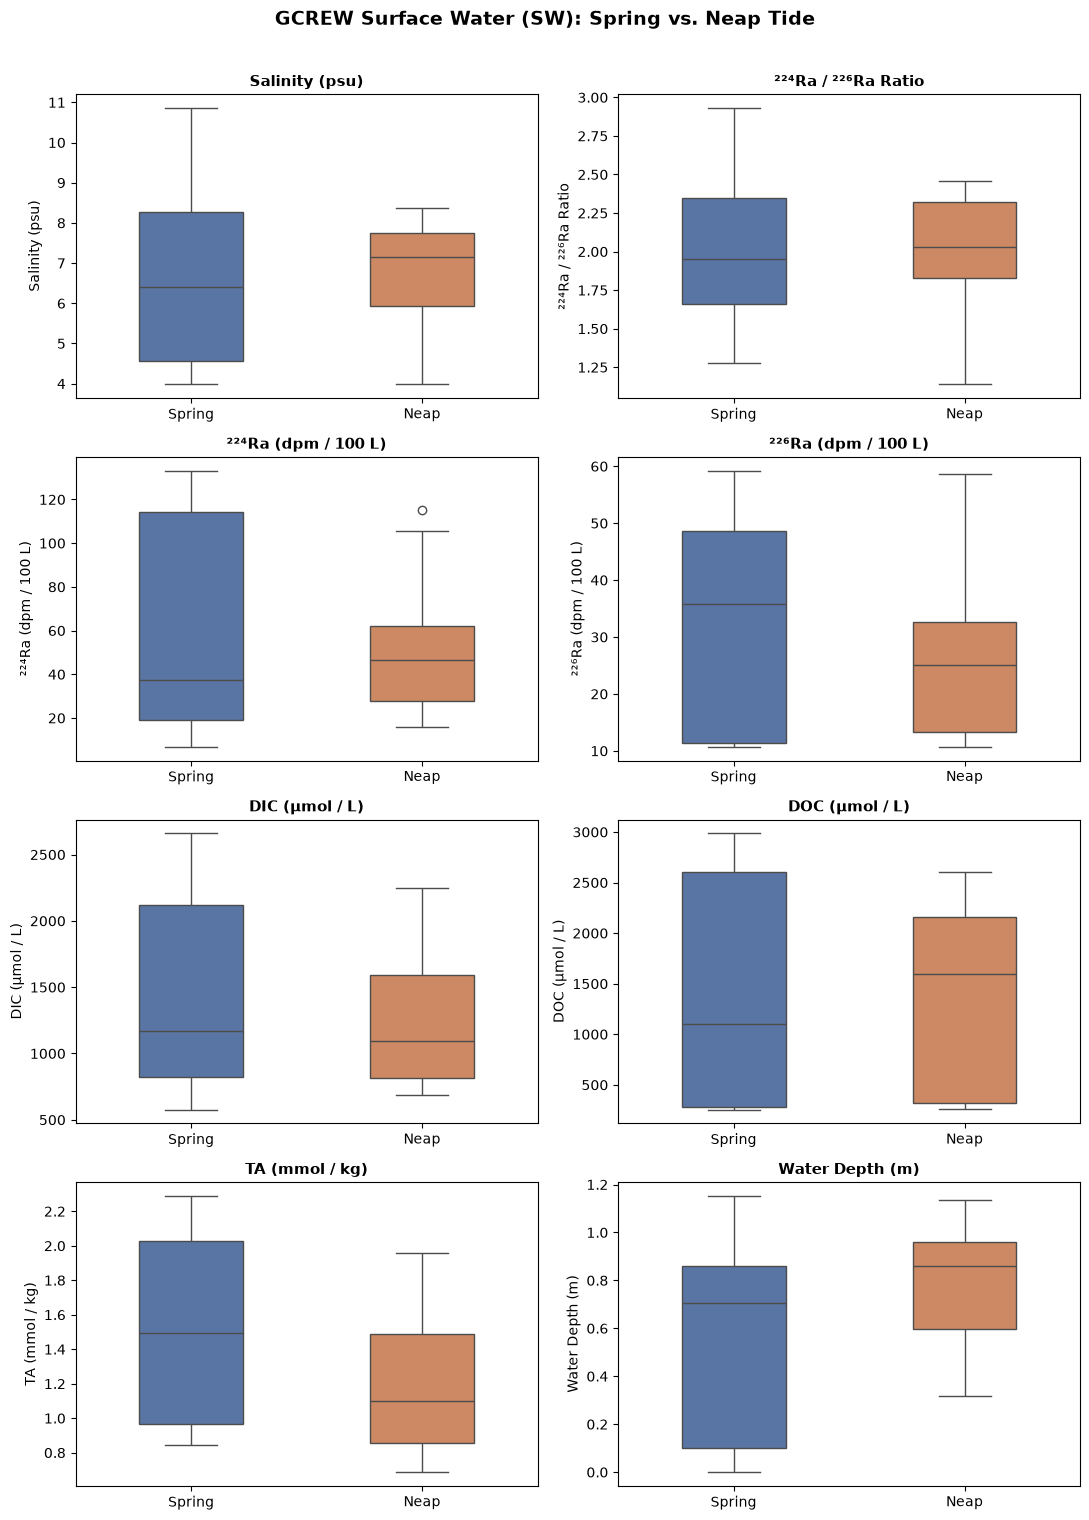

In [70]:
sw_gcrew = data_gcrew[data_gcrew['Sample_Type'] == 'SW'].copy()

gcrew_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'DOC_umolL', 'TA_mmolkg', 'water_depth'
]

var_labels = {
    'Salinity': 'Salinity (psu)',
    'Ra224_226': '²²⁴Ra / ²²⁶Ra Ratio',
    'Ra224_dpm100L': '²²⁴Ra (dpm / 100 L)',
    'Ra226_dpm100L': '²²⁶Ra (dpm / 100 L)',
    'DIC_umolL': 'DIC (µmol / L)',
    'DOC_umolL': 'DOC (µmol / L)',
    'TA_mmolkg': 'TA (mmol / kg)',
    'water_depth': 'Water Depth (m)'
}

fig, axes = plt.subplots(4, 2, figsize=(11, 15))
axes = axes.flatten()

for i, var in enumerate(gcrew_vars):
    ax = axes[i]
    
    sns.boxplot(
        data=sw_gcrew, x='Tidal_Cycle', y=var,
        order=['spring', 'neap'],
        hue='Tidal_Cycle',
        palette={'spring': '#4C72B0', 'neap': '#DD8452'},
        legend=False,
        width=0.45, ax=ax
    )
    
    ax.set_title(var_labels[var], fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Spring', 'Neap'], fontsize=10)
    ax.set_ylabel(var_labels[var], fontsize=10)

fig.suptitle('GCREW Surface Water (SW): Spring vs. Neap Tide', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, "GCREW-surfacewater-tide-boxplots")
plt.show()

I lumped together all seasons, and there appears to be no significant differences between tidal cycles. I'm thinking I should split up the seasons to compare tidal cycles.

=== GCREW SW Sample Counts ===
Tidal_Cycle  neap  spring
Season                   
Summer 2023    13      13
Winter 2024    12      13
Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\GCREW-surfacewater--tide-season-boxplots.png


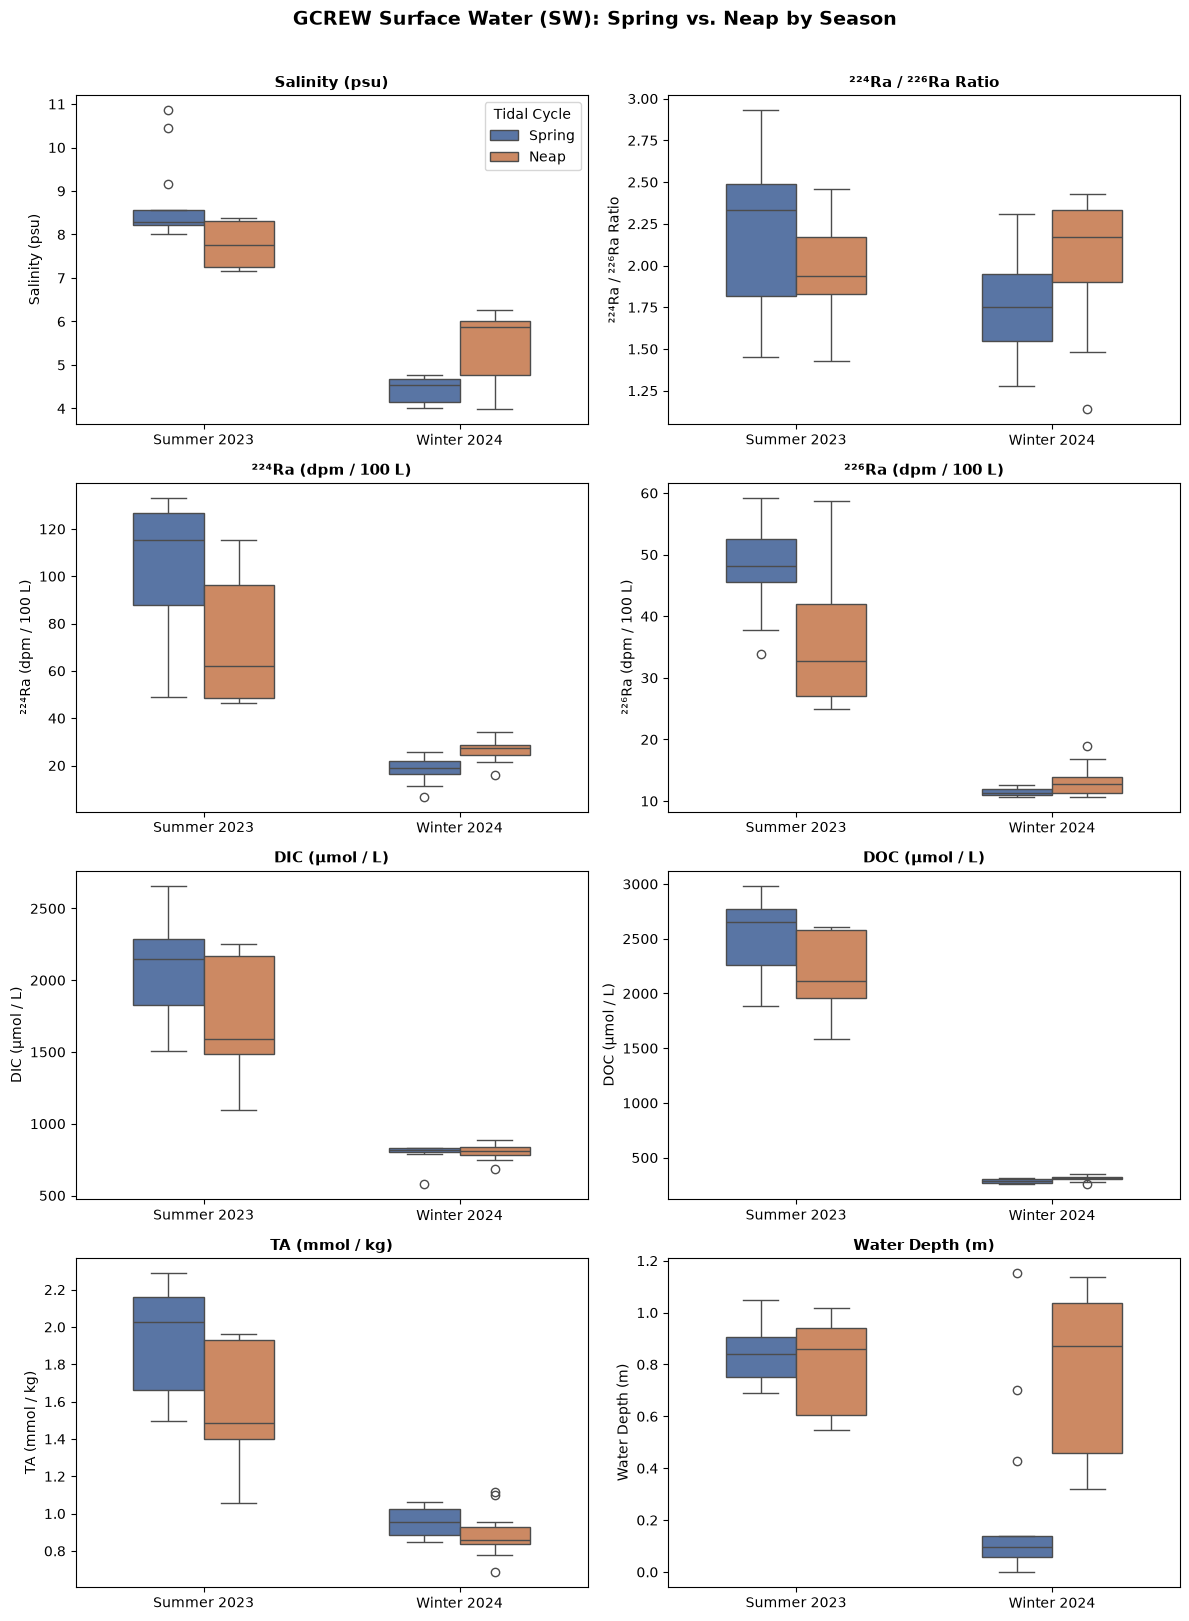

In [71]:
sw_gcrew = data_gcrew[data_gcrew['Sample_Type'] == 'SW'].copy()

# Check sample counts per Season x Tidal_Cycle
print("=== GCREW SW Sample Counts ===")
print(pd.crosstab(sw_gcrew['Season'], sw_gcrew['Tidal_Cycle']))

gcrew_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'DOC_umolL', 'TA_mmolkg', 'water_depth'
]

var_labels = {
    'Salinity': 'Salinity (psu)',
    'Ra224_226': '²²⁴Ra / ²²⁶Ra Ratio',
    'Ra224_dpm100L': '²²⁴Ra (dpm / 100 L)',
    'Ra226_dpm100L': '²²⁶Ra (dpm / 100 L)',
    'DIC_umolL': 'DIC (µmol / L)',
    'DOC_umolL': 'DOC (µmol / L)',
    'TA_mmolkg': 'TA (mmol / kg)',
    'water_depth': 'Water Depth (m)'
}

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.flatten()

for i, var in enumerate(gcrew_vars):
    ax = axes[i]
    
    sns.boxplot(
        data=sw_gcrew, x='Season', y=var,
        hue='Tidal_Cycle',
        order=['Summer 2023', 'Winter 2024'],
        hue_order=['spring', 'neap'],
        palette={'spring': '#4C72B0', 'neap': '#DD8452'},
        width=0.55, ax=ax
    )
    
    ax.set_title(var_labels[var], fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(var_labels[var], fontsize=10)
    
    if i == 0:
        handles, _ = ax.get_legend_handles_labels()
        ax.legend(handles[:2], ['Spring', 'Neap'], title='Tidal Cycle', frameon=True)
    else:
        ax.get_legend().remove()

fig.suptitle('GCREW Surface Water (SW): Spring vs. Neap by Season', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, "GCREW-surfacewater--tide-season-boxplots")
plt.show()

I'm not sure why neap appears to have a bigger spread of water depth in the summer. I need to check the master spreadsheet to make sure data was copied over correctly. 

Even amongst each season there doesn't appear to be any significant differences. I will run statistics for both situations.

In [20]:
sw_gcrew = data_gcrew[data_gcrew['Sample_Type'] == 'SW'].copy()

gcrew_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'DOC_umolL', 'TA_mmolkg', 'water_depth'
]

pooled_results = []

for var in gcrew_vars:
    spring = sw_gcrew[sw_gcrew['Tidal_Cycle'] == 'spring'][var].dropna()
    neap = sw_gcrew[sw_gcrew['Tidal_Cycle'] == 'neap'][var].dropna()
    
    if len(spring) >= 2 and len(neap) >= 2:
        u_stat, p_mwu = stats.mannwhitneyu(spring, neap, alternative='two-sided')
        lev_stat, p_lev = stats.levene(spring, neap, center='median')
        
        pooled_results.append({
            'Variable': var,
            'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})",
            'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})",
            'p_Median (MWU)': round(p_mwu, 4),
            'p_Variability (Levene)': round(p_lev, 4)
        })
    else:
        pooled_results.append({
            'Variable': var,
            'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})" if len(spring) else "N/A (0)",
            'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})" if len(neap) else "N/A (0)",
            'p_Median (MWU)': None,
            'p_Variability (Levene)': None
        })

tidal_pooled_stats = pd.DataFrame(pooled_results)

valid = tidal_pooled_stats['p_Median (MWU)'].notna()
tidal_pooled_stats.loc[valid, 'p_Median_adj'] = stats.false_discovery_control(
    tidal_pooled_stats.loc[valid, 'p_Median (MWU)'], method='bh'
).round(4)

tidal_pooled_stats['Significant Shift?'] = tidal_pooled_stats['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

tidal_pooled_stats

,Variable,Spring Med (n),Neap Med (n),p_Median (MWU),p_Variability (Levene),p_Median_adj,Significant Shift?
0,Salinity,6.40 (26),7.15 (25),0.7274,0.0000,0.9362,no
1,Ra224_226,1.95 (24),2.03 (25),0.9362,0.1144,0.9362,no
2,Ra224_dpm100L,37.45 (26),46.40 (25),0.8951,0.0044,0.9362,no
3,Ra226_dpm100L,35.80 (24),25.00 (25),0.4120,0.0033,0.9362,no
4,DIC_umolL,1170.18 (26),1094.00 (25),0.5217,0.0888,0.9362,no
5,DOC_umolL,1098.95 (26),1596.04 (24),0.7194,0.0902,0.9362,no
6,TA_mmolkg,1.50 (25),1.10 (25),0.0991,0.0605,0.3964,no
7,water_depth,0.70 (26),0.86 (25),0.0200,0.0296,0.1600,no


MWU results: there is only a statistical difference in water depth, but there is no significant difference after the Benjamini-Hochberg (BH) adjustment, which controls false discovery rate. I don't really understand what this means. I'm trying to figure it out.

Levene's results: there is significantly more spread in salinity, 224Ra, 226Ra, and water depth in one tidal cycle than the other. I will add ranges to these tables to determine which cycle has more spread (I'd suspect spring tide). 

In [21]:
sw_gcrew = data_gcrew[data_gcrew['Sample_Type'] == 'SW'].copy()

gcrew_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'DOC_umolL', 'TA_mmolkg', 'water_depth'
]

seasonal_tidal_results = []

for season in ['Summer 2023', 'Winter 2024']:
    sub_season = sw_gcrew[sw_gcrew['Season'] == season]
    
    for var in gcrew_vars:
        spring = sub_season[sub_season['Tidal_Cycle'] == 'spring'][var].dropna()
        neap = sub_season[sub_season['Tidal_Cycle'] == 'neap'][var].dropna()
        
        if len(spring) >= 2 and len(neap) >= 2:
            u_stat, p_mwu = stats.mannwhitneyu(spring, neap, alternative='two-sided')
            lev_stat, p_lev = stats.levene(spring, neap, center='median')
            
            seasonal_tidal_results.append({
                'Season': season,
                'Variable': var,
                'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})",
                'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})",
                'p_Median (MWU)': round(p_mwu, 4),
                'p_Variability (Levene)': round(p_lev, 4)
            })
        else:
            seasonal_tidal_results.append({
                'Season': season,
                'Variable': var,
                'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})" if len(spring) else "N/A (0)",
                'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})" if len(neap) else "N/A (0)",
                'p_Median (MWU)': None,
                'p_Variability (Levene)': None
            })

tidal_by_season_stats = pd.DataFrame(seasonal_tidal_results)

# Adjust p-values separately within Summer (8 tests) and Winter (8 tests)
for season in ['Summer 2023', 'Winter 2024']:
    mask = (tidal_by_season_stats['Season'] == season) & (tidal_by_season_stats['p_Median (MWU)'].notna())
    tidal_by_season_stats.loc[mask, 'p_Median_adj'] = stats.false_discovery_control(
        tidal_by_season_stats.loc[mask, 'p_Median (MWU)'], method='bh'
    ).round(4)

tidal_by_season_stats['Significant Shift?'] = tidal_by_season_stats['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

tidal_by_season_stats

,Season,Variable,Spring Med (n),Neap Med (n),p_Median (MWU),p_Variability (Levene),p_Median_adj,Significant Shift?
0,Summer 2023,Salinity,8.29 (13),7.76 (13),0.0355,0.9311,0.0536,no
1,Summer 2023,Ra224_226,2.33 (13),1.94 (13),0.1438,0.3390,0.1643,no
2,Summer 2023,Ra224_dpm100L,115.20 (13),62.20 (13),0.0035,0.8534,0.0140,YES
3,Summer 2023,Ra226_dpm100L,48.20 (13),32.70 (13),0.0018,0.1591,0.0140,YES
4,Summer 2023,DIC_umolL,2150.53 (13),1593.54 (13),0.0313,0.6401,0.0536,no
5,Summer 2023,DOC_umolL,2652.57 (13),2115.56 (13),0.0402,0.9378,0.0536,no
6,Summer 2023,TA_mmolkg,2.03 (13),1.49 (13),0.0066,0.6216,0.0176,YES
7,Summer 2023,water_depth,0.84 (13),0.86 (13),0.8375,0.0760,0.8375,no
8,Winter 2024,Salinity,4.54 (13),5.88 (12),0.0036,0.0424,0.0096,YES
9,Winter 2024,Ra224_226,1.75 (11),2.17 (12),0.0694,0.5504,0.1044,no


MWU results: there were significant differences in salinity, 224Ra, 226Ra, DIC, DOC and TA in the summer season between tidal cycles and salinity 224Ra, DOC, and water depth in the winter season.

Levene's: only two significant spread differences in the winter- salinity and 226Ra. 

Next, I will analyze seasonal variability in the TASK dataset.

In [23]:
# inspect unique values in Season 
print("=== Unique Seasons in TASK ===")
print(data_task['Season'].unique()) 

# cross-tabulate sample counts across Season and Sample_Type
print("\n=== Sample Counts by Season and Sample Type ===") 
task_counts = pd.crosstab(
    index=data_task['Season'],        # row categories
    columns=data_task['Sample_Type']  # column categories
) 

display(task_counts)

=== Unique Seasons in TASK ===
<StringArray>
[  'Fall 2023', 'Spring 2024', 'Summer 2024',   'Fall 2024', 'Winter 2025',
 'Spring 2025',   'Fall 2026']
Length: 7, dtype: str

=== Sample Counts by Season and Sample Type ===


Sample_Type,GW,PW,SW
Season,,,
Fall 2023,0,0,22
Fall 2024,2,2,24
Fall 2026,0,5,13
Spring 2024,0,0,24
Spring 2025,1,0,24
Summer 2024,0,0,23
Winter 2025,2,0,12


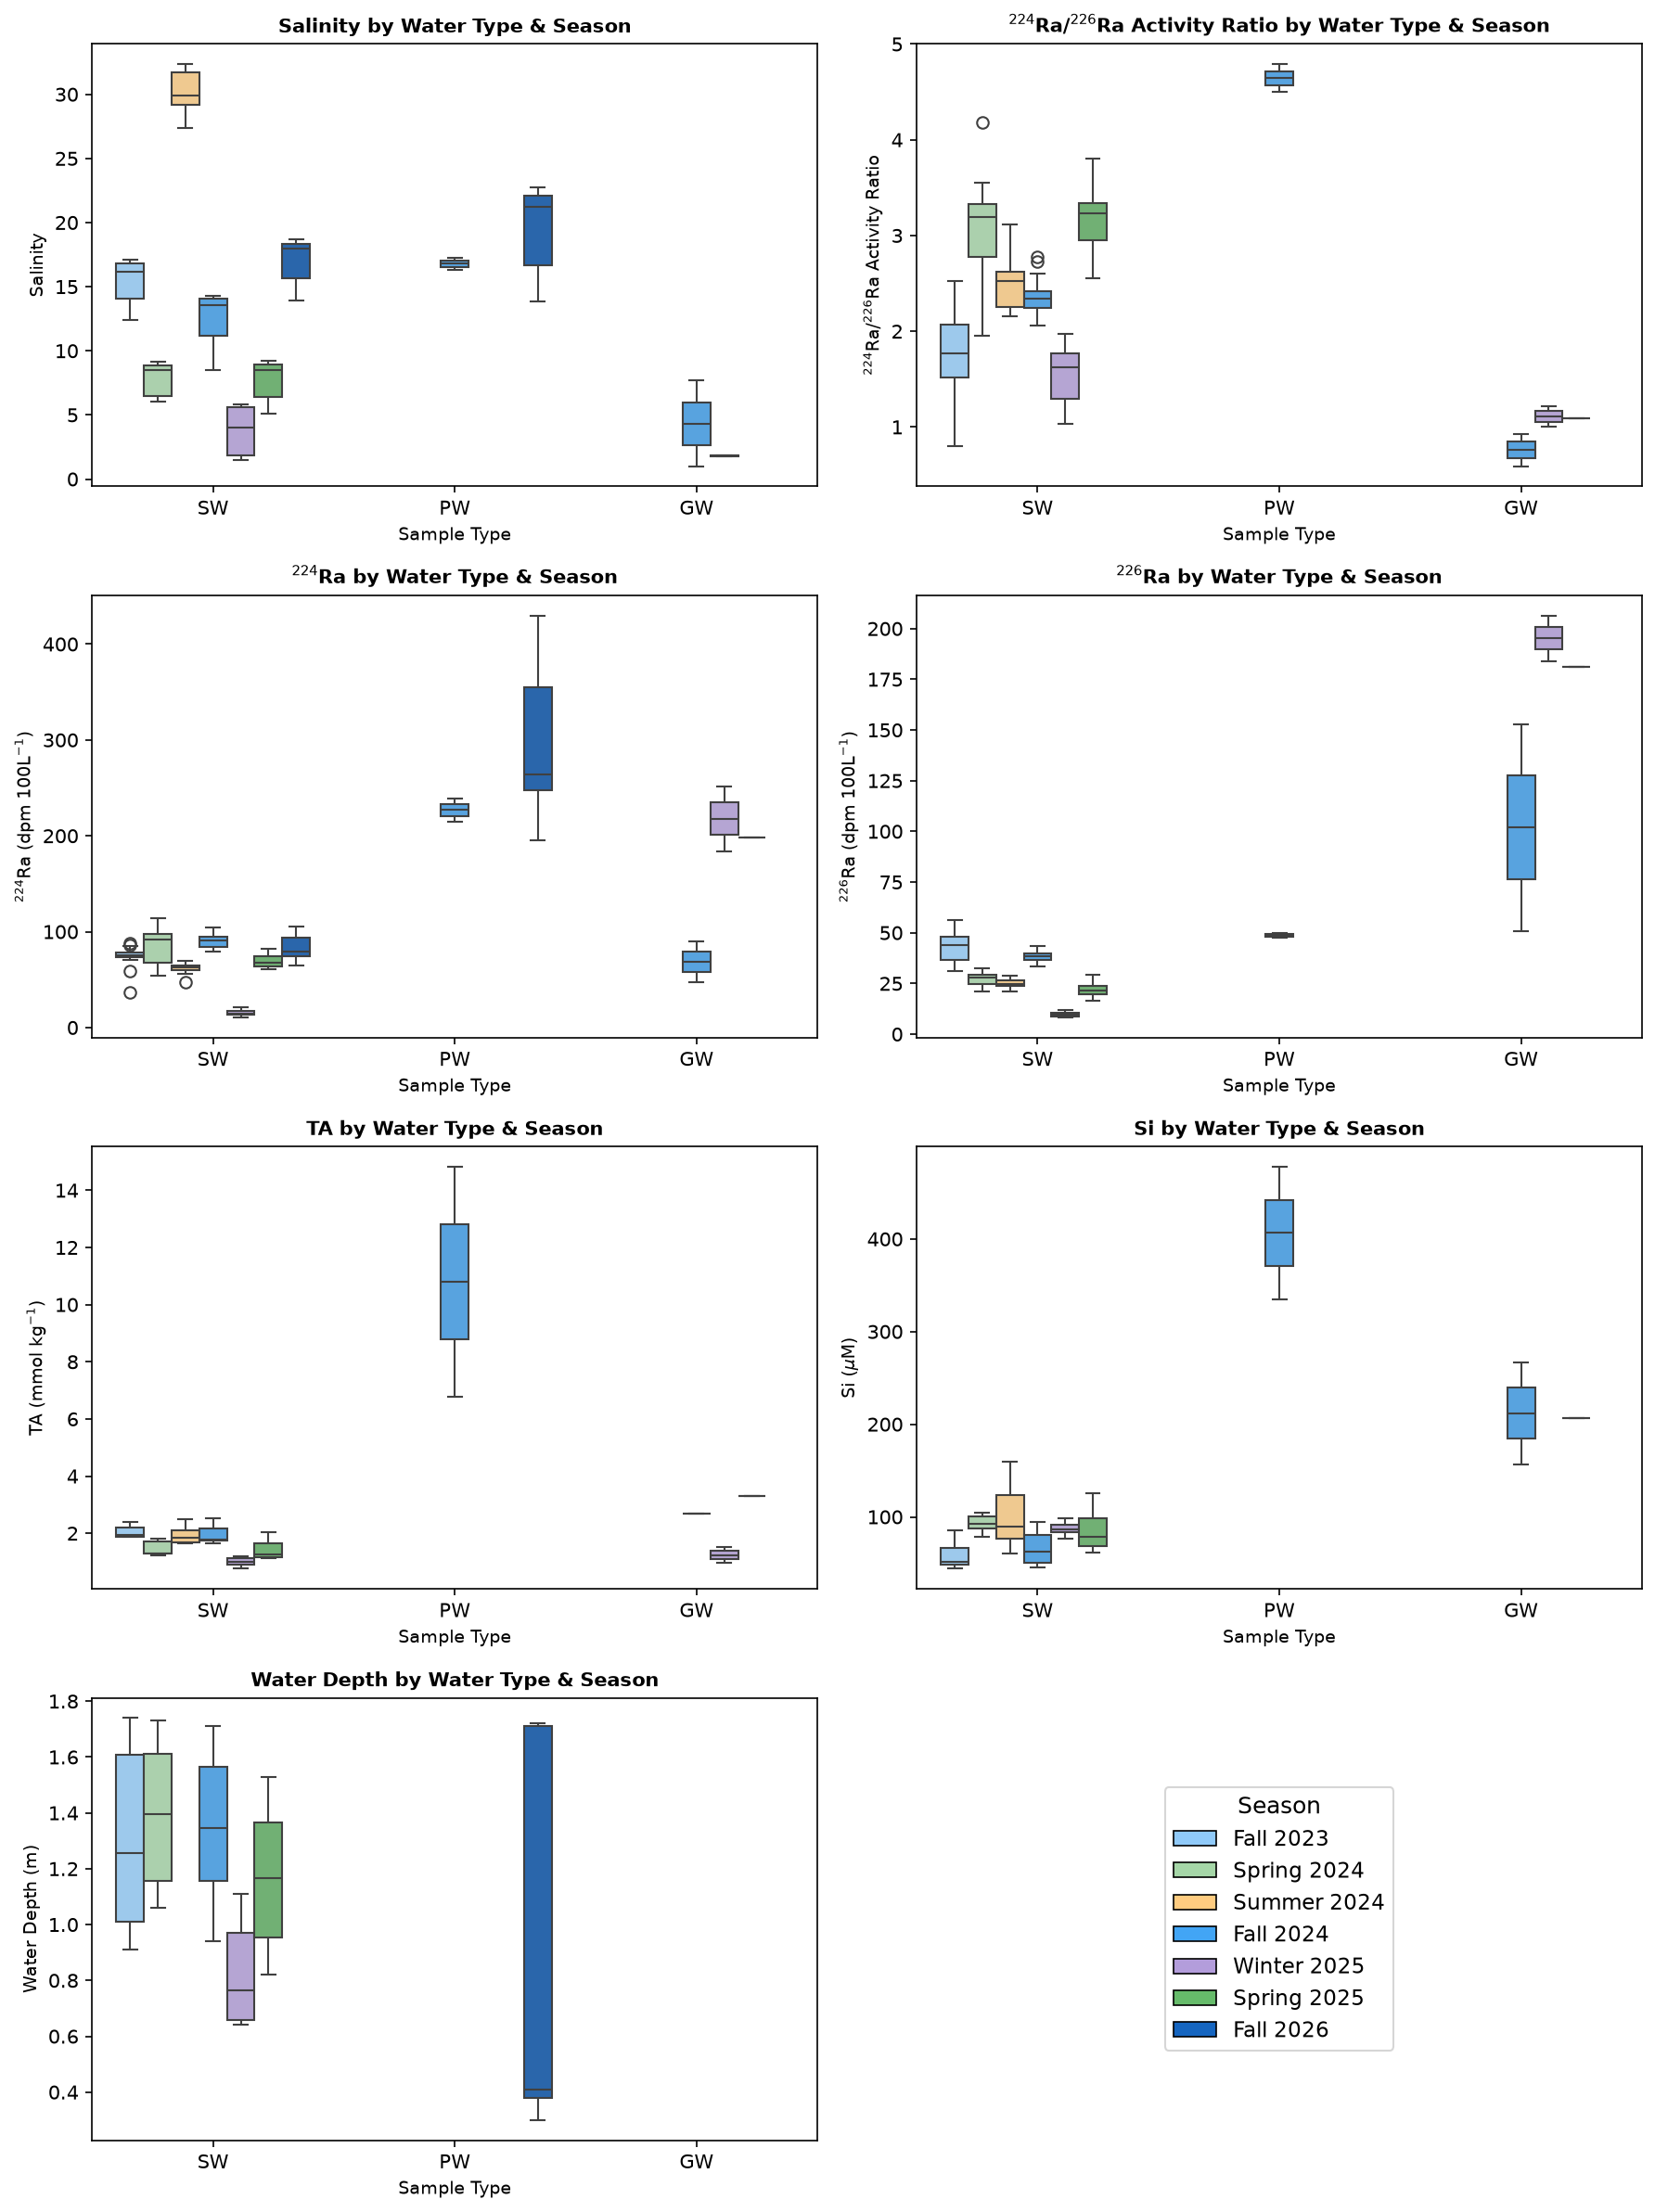

In [27]:
import re

# 1. Define color shades per season family (light-to-dark for multiple years)
season_palettes = {
    'winter': ['#b39ddb', '#7e57c2', '#4527a0'],  # Purples
    'spring': ['#a5d6a7', '#66bb6a', '#2e7d32'],  # Greens
    'summer': ['#ffcc80', '#ffa726', '#ef6c00'],  # Oranges
    'fall':   ['#90caf9', '#42a5f5', '#1565c0'],  # Blues
}

# 2. Sort unique seasons chronologically (Year first, then Winter -> Spring -> Summer -> Fall)
season_order_map = {'winter': 0, 'spring': 1, 'summer': 2, 'fall': 3, 'autumn': 3}

def sort_key(label):
    year_match = re.search(r'(\d{4})', str(label))
    year = int(year_match.group(1)) if year_match else 0
    s_rank = next((rank for name, rank in season_order_map.items() if name in str(label).lower()), 99)
    return (year, s_rank, str(label))

unique_seasons = sorted(data_task['Season'].dropna().unique(), key=sort_key)

# 3. Assign a distinct shade within each season's color family
custom_palette = {}
family_counts = {k: 0 for k in season_palettes}

for s in unique_seasons:
    s_lower = str(s).lower()
    matched_family = next((fam for fam in season_palettes if fam in s_lower), None)
    if matched_family:
        idx = family_counts[matched_family] % len(season_palettes[matched_family])
        custom_palette[s] = season_palettes[matched_family][idx]
        family_counts[matched_family] += 1
    else:
        custom_palette[s] = '#9e9e9e'  # Fallback gray if an unexpected label appears

# 4. Build the 4x2 figure
fig, axes = plt.subplots(4, 2, figsize=(12, 16), dpi=150)

plot_specs = [
    (axes[0, 0], 'Salinity',      'Salinity by Water Type & Season',                        'Salinity'),
    (axes[0, 1], 'Ra224_226',     '$^{224}$Ra/$^{226}$Ra Activity Ratio by Water Type & Season', '$^{224}$Ra/$^{226}$Ra Activity Ratio'),
    (axes[1, 0], 'Ra224_dpm100L', '$^{224}$Ra by Water Type & Season',                       r'$^{224}$Ra (dpm 100L$^{-1}$)'),
    (axes[1, 1], 'Ra226_dpm100L', '$^{226}$Ra by Water Type & Season',                       r'$^{226}$Ra (dpm 100L$^{-1}$)'),
    (axes[2, 0], 'TA_mmolkg',     'TA by Water Type & Season',                               r'TA (mmol kg$^{-1}$)'),
    (axes[2, 1], 'Si_uM',         'Si by Water Type & Season',                               r'Si ($\mu$M)'),
    (axes[3, 0], 'Depth_m',       'Water Depth by Water Type & Season',                     'Water Depth (m)'),
]

for ax, col, title, ylabel in plot_specs:
    sns.boxplot(
        data=data_task, x='Sample_Type', y=col,
        hue='Season', hue_order=unique_seasons,
        palette=custom_palette, legend=False, ax=ax
    )
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Sample Type', fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)

# 5. Put a single master legend in the empty bottom-right subplot
axes[3, 1].axis('off')
handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=custom_palette[s], edgecolor='black', linewidth=0.8)
    for s in unique_seasons
]
axes[3, 1].legend(
    handles, unique_seasons,
    title='Season', title_fontsize=12, fontsize=11,
    loc='center', frameon=True, ncol=1
)

plt.tight_layout()
plt.show()

Based on the boxplots, salinity appears to be statistically different in SW between seasons, and winter looks to be different than the other seasons in the ratio, Ra isotpes, and TA. There also appears to be some isotope and seasonal differences in GW. 

This figure is ugly. I'm going to test to make sure there are no significant differences amongst individual seasons (e.g. spring 2024 vs spring 2025). If there are no differences, I will lump them together to compare fall, winter, spring, and summer. This analysis will only be applicable to SW because PW and GW counts are too small for statistical tests. I will summarize PW and GW descriptively like I did for GCREW.

I will do a Mann-Whitney U test for the spring (two seasons) and a Kruskal-Wallis test for the fall (three seasons). Below is the Mann-Whitney U.

In [29]:
sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

spring_results = []

for var in task_vars:
    s24 = sw_task[sw_task['Season'] == 'Spring 2024'][var].dropna()
    s25 = sw_task[sw_task['Season'] == 'Spring 2025'][var].dropna()
    
    if len(s24) >= 2 and len(s25) >= 2:
        u_stat, p_mwu = stats.mannwhitneyu(s24, s25, alternative='two-sided')
        lev_stat, p_lev = stats.levene(s24, s25, center='median')
        
        spring_results.append({
            'Variable': var,
            'Spring 2024 Med (n)': f"{s24.median():.2f} ({len(s24)})",
            'Spring 2025 Med (n)': f"{s25.median():.2f} ({len(s25)})",
            'p_Median (MWU)': round(p_mwu, 4),
            'p_Variability (Levene)': round(p_lev, 4)
        })
    else:
        spring_results.append({
            'Variable': var,
            'Spring 2024 Med (n)': f"{s24.median():.2f} ({len(s24)})" if len(s24) else "N/A (0)",
            'Spring 2025 Med (n)': f"{s25.median():.2f} ({len(s25)})" if len(s25) else "N/A (0)",
            'p_Median (MWU)': None,
            'p_Variability (Levene)': None
        })

spring_interannual_df = pd.DataFrame(spring_results)

valid = spring_interannual_df['p_Median (MWU)'].notna()
spring_interannual_df.loc[valid, 'p_Median_adj'] = stats.false_discovery_control(
    spring_interannual_df.loc[valid, 'p_Median (MWU)'], method='bh'
).round(4)

spring_interannual_df['Different Across Years?'] = spring_interannual_df['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

spring_interannual_df

,Variable,Spring 2024 Med (n),Spring 2025 Med (n),p_Median (MWU),p_Variability (Levene),p_Median_adj,Different Across Years?
0,Salinity,8.47 (24),8.50 (24),0.9589,0.6456,0.9589,no
1,Ra224_226,3.20 (24),3.24 (24),0.3807,0.0685,0.4442,no
2,Ra224_dpm100L,92.15 (24),67.30 (24),0.0097,0.0012,0.0226,YES
3,Ra226_dpm100L,28.00 (24),21.40 (24),0.0000,0.8825,0.0000,YES
4,TA_mmolkg,1.30 (24),1.24 (24),0.0712,0.4845,0.0997,no
5,Si_uM,92.50 (24),78.50 (24),0.0232,0.0015,0.0406,YES
6,Depth_m,1.40 (24),1.17 (24),0.0038,0.9238,0.0133,YES


MWU results: there is a statistical difference in 224Ra, 226Ra, Si, and water depth between both spring seasons. Significantly higher water depth led to the release of more 224Ra, 226Ra, and Si? I don't think so since the Levene test revealed a similar spread aka tidal range between seasons. Spring 2025 probably had a lower low and stronger gradient. Need to check this out. Maybe more PW/GW influence in 2024. But why is water depth significantly higher the previous year? Recent rain event? Stronger tidal forcing (probably not because salinity the same...)?

Levene results: there is a significant difference in spread in 224Ra and Si. 

In [30]:
sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

fall_results = []

for var in task_vars:
    f23 = sw_task[sw_task['Season'] == 'Fall 2023'][var].dropna()
    f24 = sw_task[sw_task['Season'] == 'Fall 2024'][var].dropna()
    f26 = sw_task[sw_task['Season'] == 'Fall 2026'][var].dropna()
    
    valid_groups = [g for g in [f23, f24, f26] if len(g) >= 2]
    
    if len(valid_groups) >= 2:
        kw_stat, p_kw = stats.kruskal(*valid_groups)
        lev_stat, p_lev = stats.levene(*valid_groups, center='median')
        
        fall_results.append({
            'Variable': var,
            'Fall 2023 Med (n)': f"{f23.median():.2f} ({len(f23)})" if len(f23) else "N/A (0)",
            'Fall 2024 Med (n)': f"{f24.median():.2f} ({len(f24)})" if len(f24) else "N/A (0)",
            'Fall 2026 Med (n)': f"{f26.median():.2f} ({len(f26)})" if len(f26) else "N/A (0)",
            'p_Median (KW)': round(p_kw, 4),
            'p_Variability (Levene)': round(p_lev, 4)
        })
    else:
        fall_results.append({
            'Variable': var,
            'Fall 2023 Med (n)': f"{f23.median():.2f} ({len(f23)})" if len(f23) else "N/A (0)",
            'Fall 2024 Med (n)': f"{f24.median():.2f} ({len(f24)})" if len(f24) else "N/A (0)",
            'Fall 2026 Med (n)': f"{f26.median():.2f} ({len(f26)})" if len(f26) else "N/A (0)",
            'p_Median (KW)': None,
            'p_Variability (Levene)': None
        })

fall_interannual_df = pd.DataFrame(fall_results)

valid = fall_interannual_df['p_Median (KW)'].notna()
fall_interannual_df.loc[valid, 'p_Median_adj'] = stats.false_discovery_control(
    fall_interannual_df.loc[valid, 'p_Median (KW)'], method='bh'
).round(4)

fall_interannual_df['Different Across Years?'] = fall_interannual_df['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

fall_interannual_df

,Variable,Fall 2023 Med (n),Fall 2024 Med (n),Fall 2026 Med (n),p_Median (KW),p_Variability (Levene),p_Median_adj,Different Across Years?
0,Salinity,16.20 (22),13.54 (24),17.95 (13),0.0000,0.8029,0.0000,YES
1,Ra224_226,1.77 (22),2.34 (24),N/A (0),0.0000,0.0006,0.0000,YES
2,Ra224_dpm100L,75.70 (22),90.40 (24),79.30 (13),0.0000,0.1058,0.0000,YES
3,Ra226_dpm100L,44.10 (22),38.20 (24),N/A (0),0.0347,0.0000,0.0607,no
4,TA_mmolkg,1.93 (22),1.77 (24),N/A (0),0.0616,0.2377,0.0862,no
5,Si_uM,51.50 (22),62.50 (24),N/A (0),0.0860,0.0945,0.1003,no
6,Depth_m,1.25 (22),1.35 (24),N/A (0),0.4953,0.1422,0.4953,no


KW results: there is a significant differnce in salinity, Ra isotopes and the ratio between the fall seasons. A difference in salinity but not water depth tells me there may have been more freshwater (GW) influence some years compared to others. Fall 2024 was the freshest, which tracks with the higher Si but not TA or 226. I need to keep in mind that some data are still in the works from the Fall 2026 campaign, and I need to revisit this analysis later.

**226Ra, Si, and TA are a shared sediment derived source to the creek and thus serve as co-tracers for PEX and SGD.

Levene results: there is a significant difference in spread in the ratio and 226Ra.

Conclusions: 4 of 7 variables in the spring and fall differ significantly across years, which means I will keep the individual sampling campaigns separate in my analysis. I will remake the boxplots for all seasons but hone in on SW only.

Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\TASK-surfacewater-season-boxplots.png


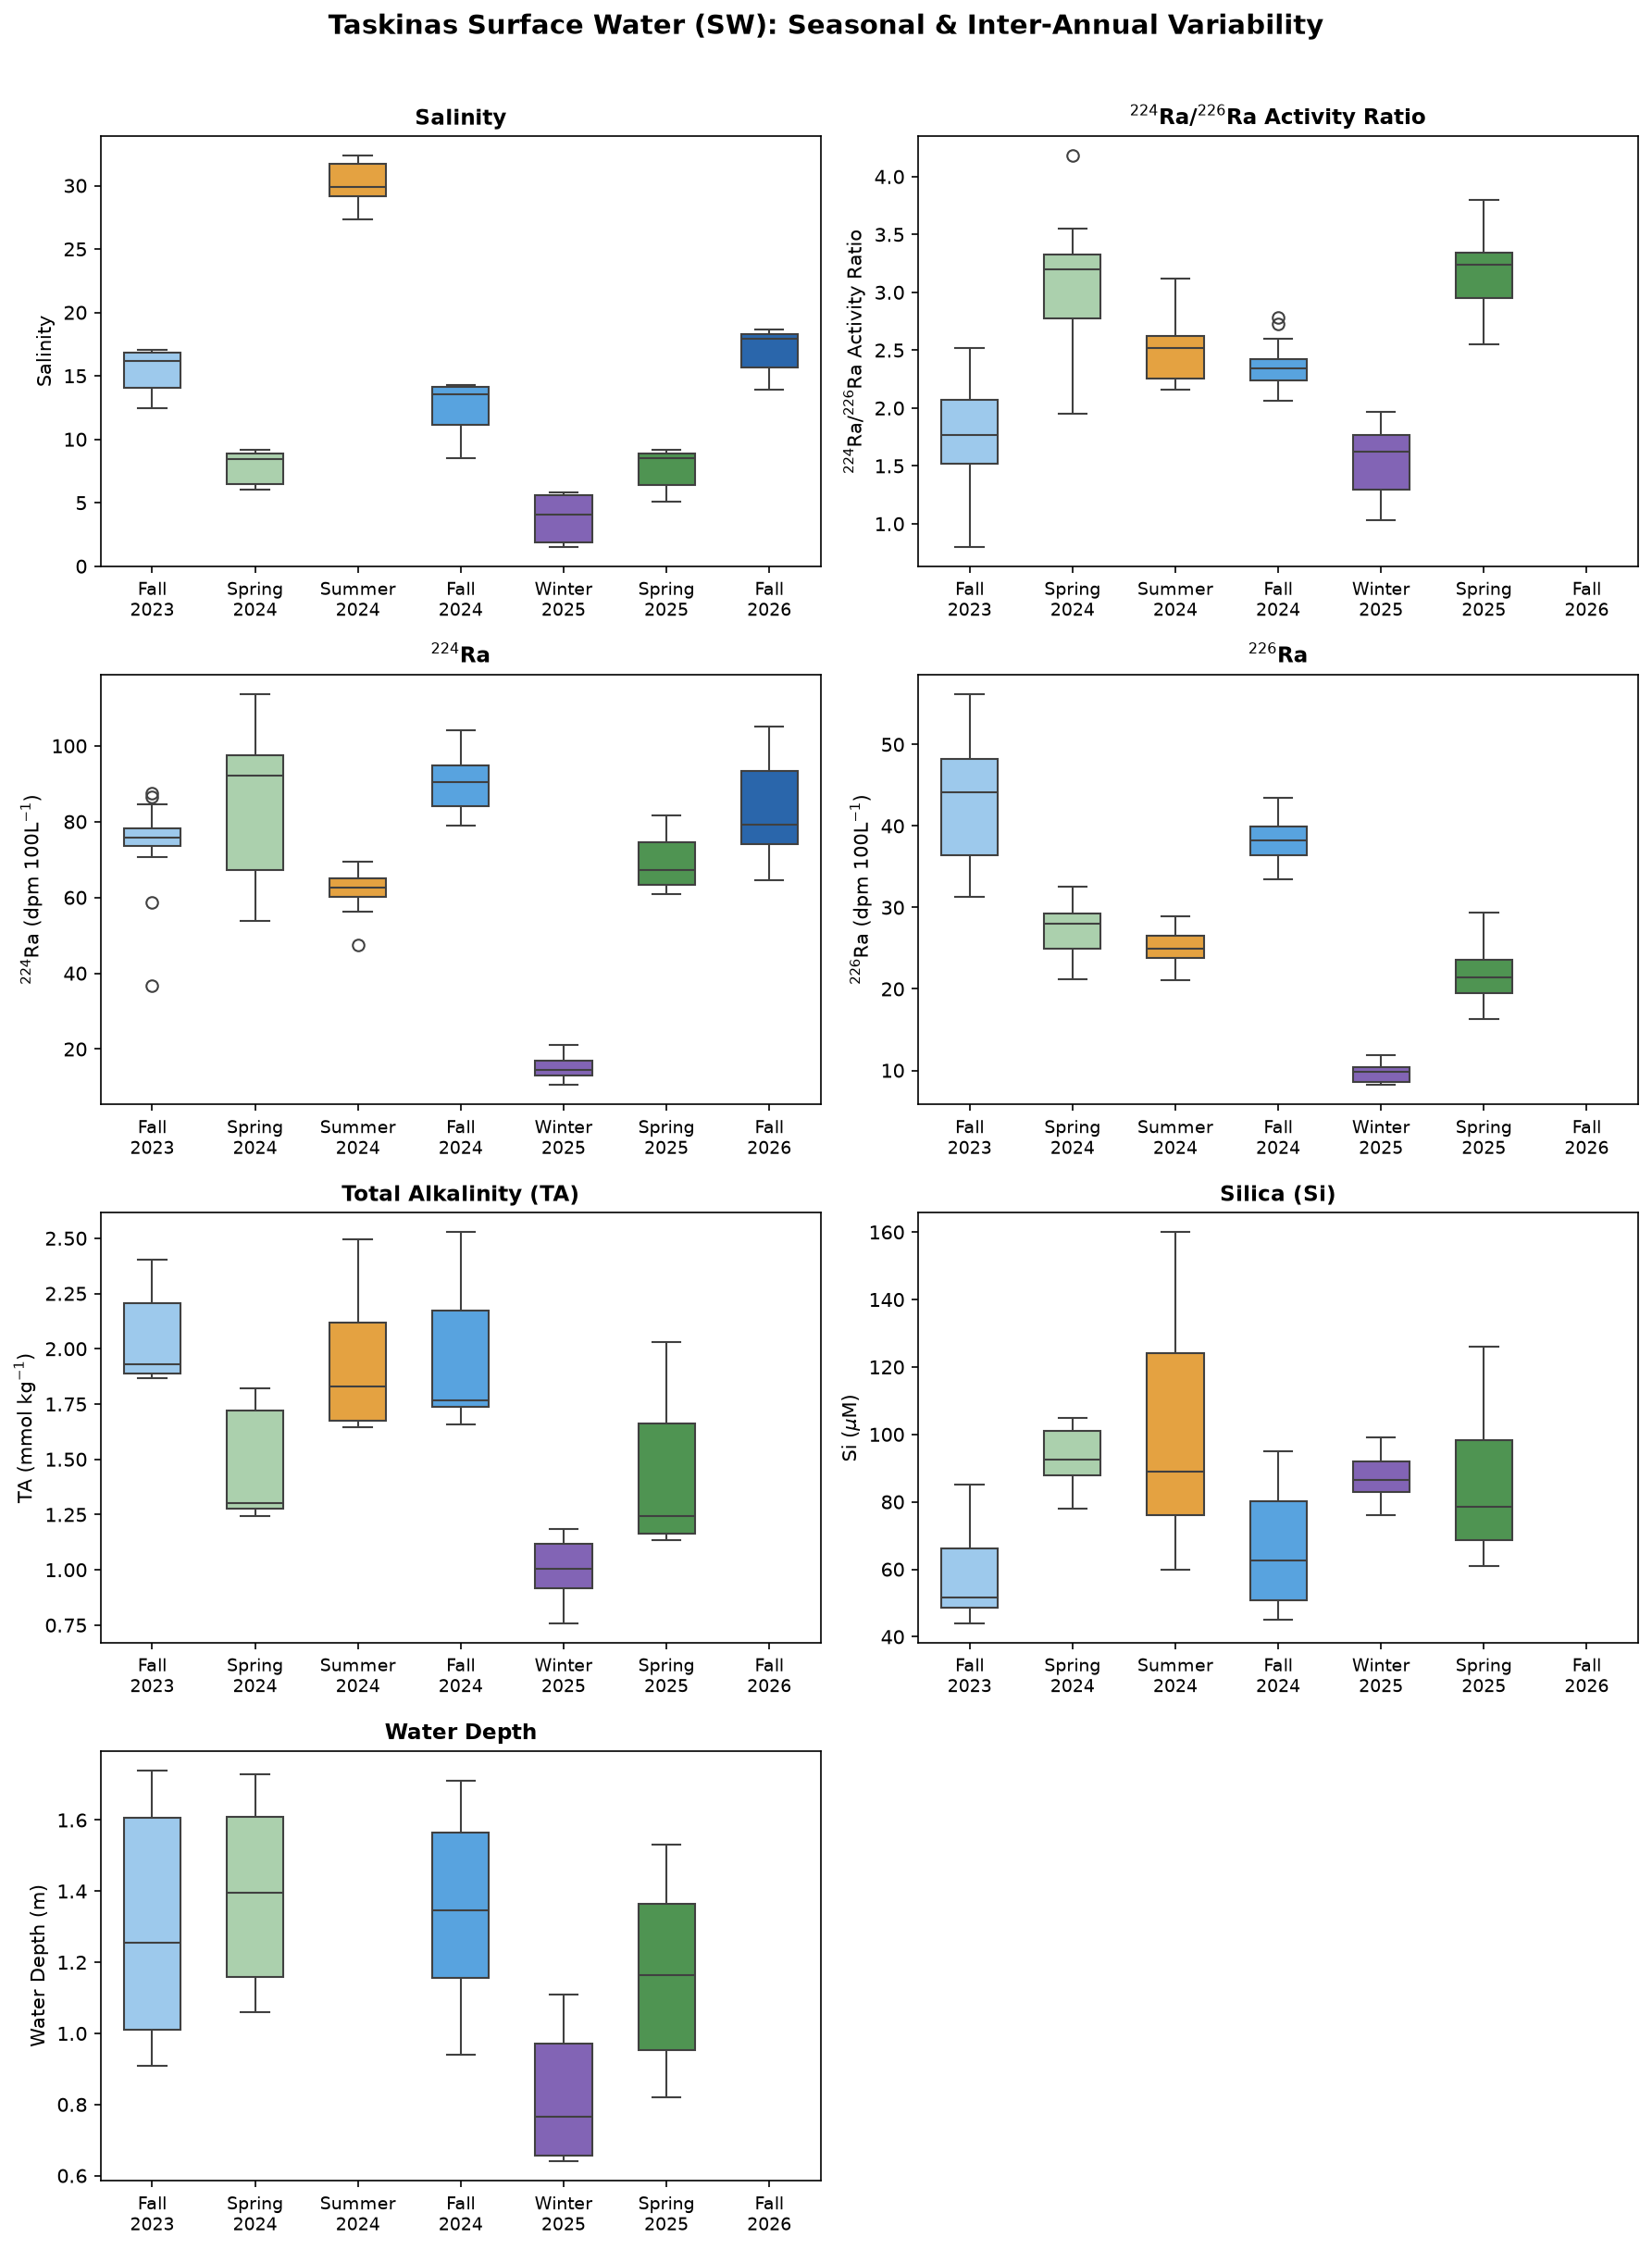

In [72]:
sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

# Chronological campaign order & color shades by season family
campaign_order = [
    'Fall 2023', 'Spring 2024', 'Summer 2024',
    'Fall 2024', 'Winter 2025', 'Spring 2025', 'Fall 2026'
]

campaign_palette = {
    'Fall 2023':   '#90caf9',  # Light Blue
    'Spring 2024': '#a5d6a7',  # Light Green
    'Summer 2024': '#ffa726',  # Orange
    'Fall 2024':   '#42a5f5',  # Medium Blue
    'Winter 2025': '#7e57c2',  # Purple
    'Spring 2025': '#43a047',  # Darker Green
    'Fall 2026':   '#1565c0',  # Dark Blue
}

short_labels = [c.replace(' ', '\n') for c in campaign_order]

plot_specs = [
    ('Salinity',      'Salinity',                              'Salinity'),
    ('Ra224_226',     '$^{224}$Ra/$^{226}$Ra Activity Ratio',  '$^{224}$Ra/$^{226}$Ra Activity Ratio'),
    ('Ra224_dpm100L', '$^{224}$Ra',                            r'$^{224}$Ra (dpm 100L$^{-1}$)'),
    ('Ra226_dpm100L', '$^{226}$Ra',                            r'$^{226}$Ra (dpm 100L$^{-1}$)'),
    ('TA_mmolkg',     'Total Alkalinity (TA)',                 r'TA (mmol kg$^{-1}$)'),
    ('Si_uM',         'Silica (Si)',                           r'Si ($\mu$M)'),
    ('Depth_m',       'Water Depth',                           'Water Depth (m)'),
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16), dpi=150)
axes = axes.flatten()

for i, (col, title, ylabel) in enumerate(plot_specs):
    ax = axes[i]
    sns.boxplot(
        data=sw_task, x='Season', y=col,
        order=campaign_order,
        hue='Season', hue_order=campaign_order,
        palette=campaign_palette,
        legend=False, width=0.55, ax=ax
    )
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_xticks(range(len(campaign_order)))
    ax.set_xticklabels(short_labels, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=10)

# Turn off the empty 8th panel
axes[7].axis('off')

fig.suptitle('Taskinas Surface Water (SW): Seasonal & Inter-Annual Variability', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, "TASK-surfacewater-season-boxplots")
plt.show()

I will run a Kruskal-Wallis test to see if any of my selected variables are different in at least one of the seven campaigns.

In [40]:
import scikit_posthocs as sp

sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

campaign_order = [
    'Fall 2023', 'Spring 2024', 'Summer 2024',
    'Fall 2024', 'Winter 2025', 'Spring 2025', 'Fall 2026'
]

task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

kw_results = []

for var in task_vars:
    groups = [sw_task[sw_task['Season'] == c][var].dropna() for c in campaign_order]
    valid_groups = [g for g in groups if len(g) >= 2]
    
    kw_stat, p_kw = stats.kruskal(*valid_groups)
    lev_stat, p_lev = stats.levene(*valid_groups, center='median')
    
    row = {
        'Variable': var,
        'Campaigns Tested': len(valid_groups),
        'H_stat (KW)': round(kw_stat, 3),
        'p_Median (KW)': round(p_kw, 4),
        'p_Variability (Levene)': round(p_lev, 4)
    }
    kw_results.append(row)

kw_summary_df = pd.DataFrame(kw_results)
kw_summary_df['p_Median_adj'] = stats.false_discovery_control(
    kw_summary_df['p_Median (KW)'], method='bh'
).round(4)
kw_summary_df['Significant Shift?'] = kw_summary_df['p_Median_adj'].apply(
    lambda p: 'YES' if p < 0.05 else 'no'
)

display(kw_summary_df)

,Variable,Campaigns Tested,H_stat (KW),p_Median (KW),p_Variability (Levene),p_Median_adj,Significant Shift?
0,Salinity,7,127.333,0.0,0.6123,0.0,YES
1,Ra224_226,6,97.247,0.0,0.0023,0.0,YES
2,Ra224_dpm100L,7,86.592,0.0,0.0000,0.0,YES
3,Ra226_dpm100L,6,110.224,0.0,0.0000,0.0,YES
4,TA_mmolkg,6,81.367,0.0,0.4836,0.0,YES
5,Si_uM,6,60.000,0.0,0.0000,0.0,YES
6,Depth_m,5,31.998,0.0,0.1212,0.0,YES


This test shows that my variables are significantly different in at least one season compared to the rest. I will run a Dunn's pairwise post-hoc test to determine where there are significant differences between campaigns. The same letter means the seasons are statistically indistinguishable, different letters mean that season is statistically significant, and two letters (e.g. ab) means the campaign sits in the middle and is not significantly different from either group a or b. 

In [45]:
sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

campaign_order = [
    'Fall 2023', 'Spring 2024', 'Summer 2024',
    'Fall 2024', 'Winter 2025', 'Spring 2025', 'Fall 2026'
]

task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

def get_cld_letters(campaigns, sig_pairs_set):
    n = len(campaigns)
    cliques = []
    for i in range(n):
        c_i = campaigns[i]
        placed = False
        for clq in cliques:
            if all((min(c_i, c_j), max(c_i, c_j)) not in sig_pairs_set for c_j in clq):
                clq.append(c_i)
                placed = True
        if not placed:
            cliques.append([c_i])
    
    maximal_cliques = [
        clq for clq in cliques
        if not any(set(clq) < set(other) for other in cliques)
    ]
    unique_cliques = []
    for clq in maximal_cliques:
        if clq not in unique_cliques:
            unique_cliques.append(clq)
            
    letters = 'abcdefghijklmnopqrstuvwxyz'
    letter_map = {c: '' for c in campaigns}
    for idx, clq in enumerate(unique_cliques):
        for c in clq:
            letter_map[c] += letters[idx]
    return letter_map

cld_summary_rows = []
all_pairwise_rows = []

for var in task_vars:
    sub = sw_task[['Season', var]].dropna()
    present_campaigns = [c for c in campaign_order if len(sub[sub['Season'] == c]) >= 2]
    
    var_pairs = []
    for i in range(len(present_campaigns)):
        for j in range(i + 1, len(present_campaigns)):
            c1, c2 = present_campaigns[i], present_campaigns[j]
            g1 = sub[sub['Season'] == c1][var]
            g2 = sub[sub['Season'] == c2][var]
            _, p_raw = stats.mannwhitneyu(g1, g2, alternative='two-sided')
            var_pairs.append({
                'Variable': var,
                'Comparison': f"{c1} vs. {c2}",
                'c1': c1,
                'c2': c2,
                'Med 1': round(g1.median(), 2),
                'Med 2': round(g2.median(), 2),
                'p_raw': round(p_raw, 4)
            })
            
    var_df = pd.DataFrame(var_pairs)
    var_df['p_adj'] = stats.false_discovery_control(var_df['p_raw'], method='bh').round(4)
    var_df['Diff?'] = var_df['p_adj'].apply(lambda p: 'YES' if p < 0.05 else 'no')
    all_pairwise_rows.append(var_df)
    
    sig_set = {
        (min(r['c1'], r['c2']), max(r['c1'], r['c2']))
        for _, r in var_df[var_df['Diff?'] == 'YES'].iterrows()
    }
    letter_map = get_cld_letters(present_campaigns, sig_set)
    
    summary_row = {'Variable': var}
    for c in campaign_order:
        if c in present_campaigns:
            med = sub[sub['Season'] == c][var].median()
            summary_row[c] = f"{med:.2f} ({letter_map[c]})"
        else:
            summary_row[c] = "N/A"
    cld_summary_rows.append(summary_row)

cld_df = pd.DataFrame(cld_summary_rows)
display(cld_df)

,Variable,Fall 2023,Spring 2024,Summer 2024,Fall 2024,Winter 2025,Spring 2025,Fall 2026
0,Salinity,16.20 (a),8.47 (b),29.87 (c),13.54 (d),4.03 (e),8.50 (b),17.95 (f)
1,Ra224_226,1.77 (a),3.20 (b),2.52 (c),2.34 (d),1.62 (a),3.24 (b),N/A
2,Ra224_dpm100L,75.70 (a),92.15 (a),62.70 (b),90.40 (c),14.50 (d),67.30 (e),79.30 (ac)
3,Ra226_dpm100L,44.10 (a),28.00 (b),24.90 (c),38.20 (d),9.80 (e),21.40 (f),N/A
4,TA_mmolkg,1.93 (a),1.30 (b),1.83 (a),1.77 (a),1.01 (c),1.24 (b),N/A
5,Si_uM,51.50 (a),92.50 (b),89.00 (b),62.50 (a),86.50 (c),78.50 (c),N/A
6,Depth_m,1.25 (a),1.40 (a),N/A,1.35 (a),0.76 (b),1.17 (c),N/A


All seasons are statistically different in salinity except for spring 2024 and spring 2025. Fall 2023 and winter 2025 are similar in 224/226 ratio and so are spring 2024 and 2025. Fall 2023 and spring 2024 are similar in 224Ra and fall 2026 sits in the middle of fall 2023 and fall 2024. All seasons are significantly different in 226Ra (this is good justification for choosing seasonal endmembers). Fall 2023, summer 2024, and fall 2024 are similar in TA, and spring 2024 and 2025 are similar. Fall 2023 and 2024 are similar in Si, and so are spring 2024 and summer 2024, and winter 2025 and spring 2025. Water depth was similar in fall 2023, spring 2024, and fall 2024.

Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\TASK-surfacewater-season-pairwise.png


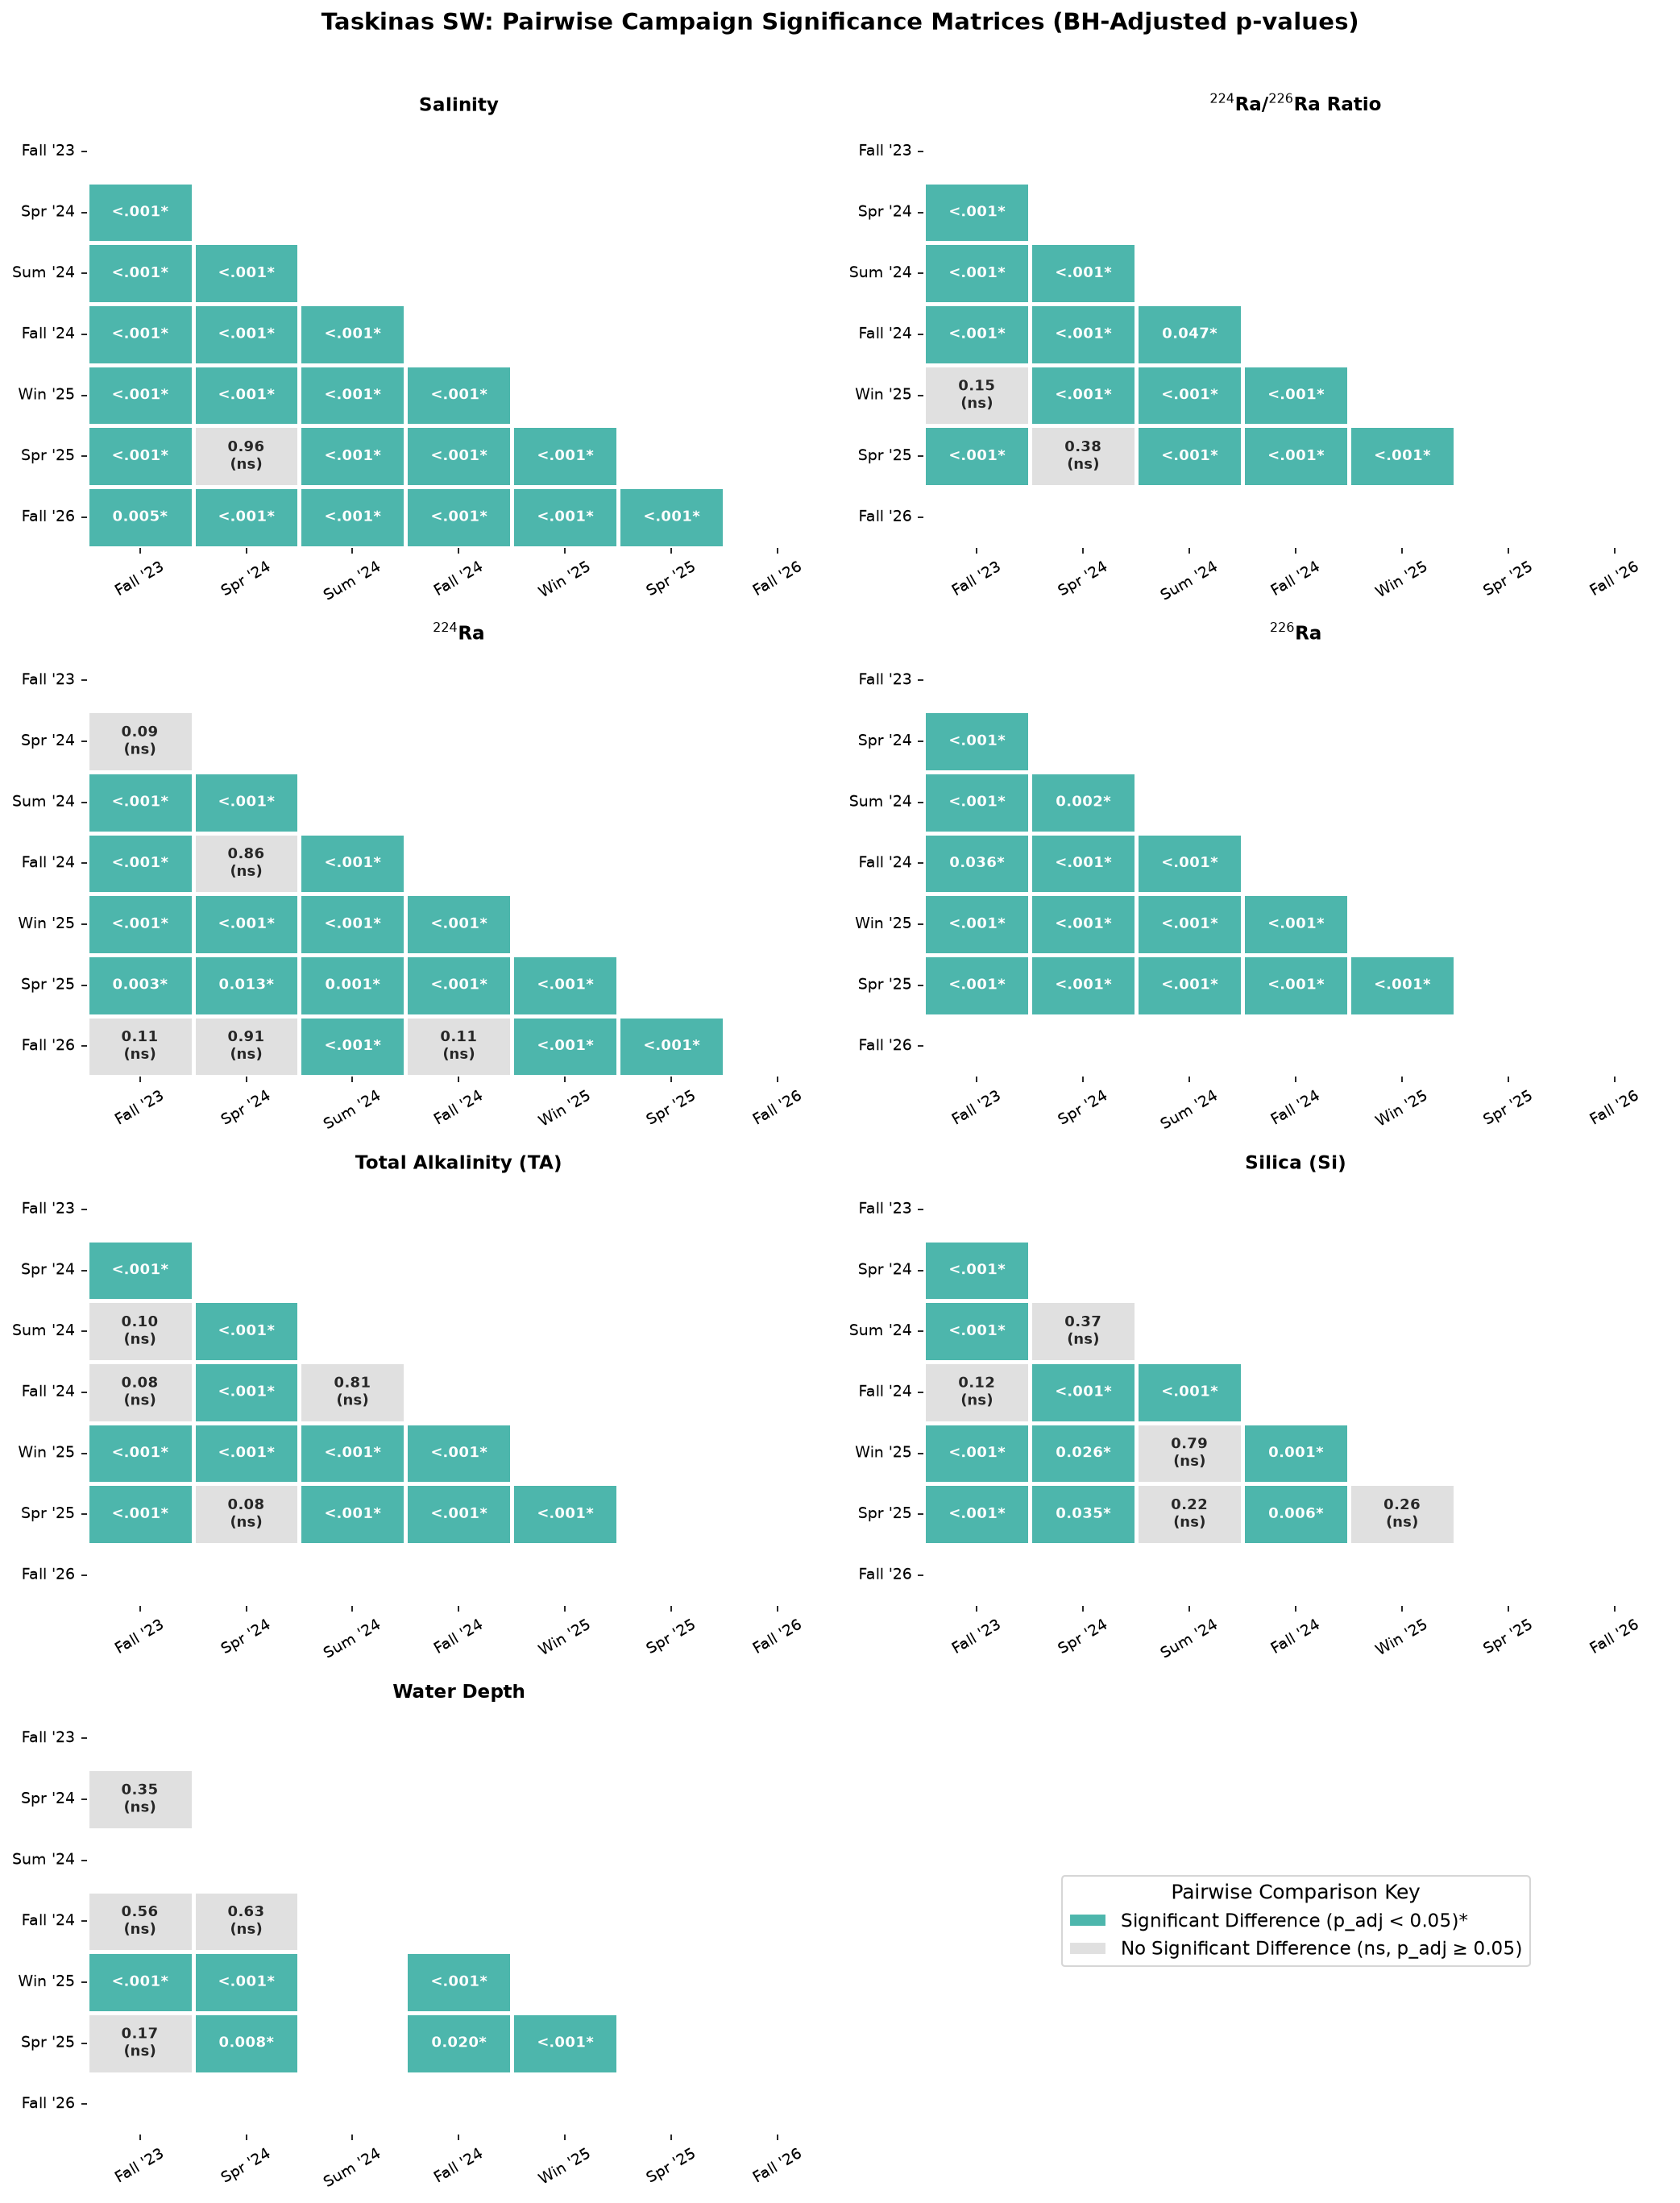

In [73]:
sw_task = data_task[data_task['Sample_Type'] == 'SW'].copy()

campaign_order = [
    'Fall 2023', 'Spring 2024', 'Summer 2024',
    'Fall 2024', 'Winter 2025', 'Spring 2025', 'Fall 2026'
]
short_names = ["Fall '23", "Spr '24", "Sum '24", "Fall '24", "Win '25", "Spr '25", "Fall '26"]

plot_specs = [
    ('Salinity',      'Salinity'),
    ('Ra224_226',     '$^{224}$Ra/$^{226}$Ra Ratio'),
    ('Ra224_dpm100L', '$^{224}$Ra'),
    ('Ra226_dpm100L', '$^{226}$Ra'),
    ('TA_mmolkg',     'Total Alkalinity (TA)'),
    ('Si_uM',         'Silica (Si)'),
    ('Depth_m',       'Water Depth'),
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18), dpi=150)
axes = axes.flatten()

for idx, (var, title) in enumerate(plot_specs):
    ax = axes[idx]
    sub = sw_task[['Season', var]].dropna()
    present = [c for c in campaign_order if len(sub[sub['Season'] == c]) >= 2]
    
    # Compute BH-adjusted pairwise p-values
    pairs = []
    for i in range(len(present)):
        for j in range(i + 1, len(present)):
            g1 = sub[sub['Season'] == present[i]][var]
            g2 = sub[sub['Season'] == present[j]][var]
            _, p_raw = stats.mannwhitneyu(g1, g2, alternative='two-sided')
            pairs.append((present[i], present[j], p_raw))
            
    p_adjs = stats.false_discovery_control([p[2] for p in pairs], method='bh')
    
    # Fill symmetric 7x7 matrix (NaN on diagonal and missing campaigns)
    p_mat = pd.DataFrame(np.nan, index=campaign_order, columns=campaign_order)
    for (c1, c2, _), p_adj in zip(pairs, p_adjs):
        p_mat.loc[c1, c2] = p_adj
        p_mat.loc[c2, c1] = p_adj
        
    # Mask upper triangle + diagonal so each pair appears only once
    mask = np.triu(np.ones_like(p_mat, dtype=bool))
    
    # Custom annotation: '*' for p < 0.001, exact value otherwise, 'ns' if >= 0.05
    annot = p_mat.copy().astype(object)
    for r in campaign_order:
        for c in campaign_order:
            val = p_mat.loc[r, c]
            if pd.isna(val):
                annot.loc[r, c] = ""
            elif val < 0.001:
                annot.loc[r, c] = "<.001*"
            elif val < 0.05:
                annot.loc[r, c] = f"{val:.3f}*"
            else:
                annot.loc[r, c] = f"{val:.2f}\n(ns)"
                
    # Binary color matrix: 1 = Significant (teal), 0 = Not Significant (light gray)
    sig_color = p_mat.map(lambda v: np.nan if pd.isna(v) else (1.0 if v < 0.05 else 0.0))
    
    sns.heatmap(
        sig_color, mask=mask, annot=annot, fmt="",
        cmap=["#e0e0e0", "#4db6ac"], vmin=0, vmax=1,
        cbar=False, linewidths=1.5, linecolor="white",
        annot_kws={"size": 8.5, "weight": "bold"},
        xticklabels=short_names, yticklabels=short_names, ax=ax
    )
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    ax.tick_params(axis='y', rotation=0, labelsize=9)

# Bottom-right legend panel
axes[7].axis('off')
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor="#4db6ac", edgecolor="white", label="Significant Difference (p_adj < 0.05)*"),
    plt.Rectangle((0, 0), 1, 1, facecolor="#e0e0e0", edgecolor="white", label="No Significant Difference (ns, p_adj ≥ 0.05)")
]
axes[7].legend(handles=legend_handles, loc="center", fontsize=11, frameon=True, title="Pairwise Comparison Key", title_fontsize=12)

fig.suptitle("Taskinas SW: Pairwise Campaign Significance Matrices (BH-Adjusted p-values)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig(fig, "TASK-surfacewater-season-pairwise")
plt.show()

This figure shows the p-values associated with the statistical differences described above. There is a lot to untangle here with seasonal differences and figuring out why. Pray for me. I will finish this analysis with PW and GW summary tables since I cant run stats on this supporting data.

In [50]:
# PW summary table
task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

sub_pw = data_task[data_task['Sample_Type'] == 'PW']
pw_rows = {}

for season in ['Fall 2024', 'Fall 2026']:
    df_s = sub_pw[sub_pw['Season'] == season][task_vars]
    pw_rows[(season, 'n')] = df_s.count()
    pw_rows[(season, 'Median')] = df_s.median().round(2)
    pw_rows[(season, 'Min')] = df_s.min().round(2)
    pw_rows[(season, 'Max')] = df_s.max().round(2)
    pw_rows[(season, 'Mean')] = df_s.mean().round(2)
    pw_rows[(season, 'SD')] = df_s.std().round(2)

pw_transposed = pd.DataFrame(pw_rows).T
pw_transposed.index.names = ['Season', 'Stat']
pw_transposed

Salinity  Ra224_226  Ra224_dpm100L  Ra226_dpm100L  \
Season    Stat                                                        
Fall 2024 n           2.00       2.00           2.00           2.00   
          Median     16.78       4.64         226.95          48.80   
          Min        16.32       4.50         214.60          47.70   
          Max        17.25       4.79         239.30          49.90   
          Mean       16.78       4.64         226.95          48.80   
          SD          0.66       0.21          17.47           1.56   
Fall 2026 n           5.00       0.00           5.00           0.00   
          Median     21.20        NaN         264.00            NaN   
          Min        13.86        NaN         194.90            NaN   
          Max        22.76        NaN         429.90            NaN   
          Mean       19.32        NaN         298.26            NaN   
          SD          3.87        NaN          93.40            NaN   

                  TA_mmolkg   Si_uM  Depth_m  
Season    Stat                                
Fall 2024 n            2.00    2.00     0.00  
          Median      10.80  406.50      NaN  
          Min          6.77  335.00      NaN  
          Max         14.83  478.00      NaN  
          Mean        10.80  406.50      NaN  
          SD           5.70  101.12      NaN  
Fall 2026 n            0.00    0.00     5.00  
          Median        NaN     NaN     0.41  
          Min           NaN     NaN     0.30  
          Max           NaN     NaN     1.72  
          Mean          NaN     NaN     0.90  
          SD            NaN     NaN     0.74

In [51]:
# GW summary table 
task_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'TA_mmolkg', 'Si_uM', 'Depth_m'
]

sub_gw = data_task[data_task['Sample_Type'] == 'GW']
gw_rows = {}

for season in ['Fall 2024', 'Winter 2025', 'Spring 2025']:
    df_s = sub_gw[sub_gw['Season'] == season][task_vars]
    gw_rows[(season, 'n')] = df_s.count()
    gw_rows[(season, 'Median')] = df_s.median().round(2)
    gw_rows[(season, 'Min')] = df_s.min().round(2)
    gw_rows[(season, 'Max')] = df_s.max().round(2)
    gw_rows[(season, 'Mean')] = df_s.mean().round(2)
    gw_rows[(season, 'SD')] = df_s.std().round(2)

gw_transposed = pd.DataFrame(gw_rows).T
gw_transposed.index.names = ['Season', 'Stat']
gw_transposed

Salinity  Ra224_226  Ra224_dpm100L  Ra226_dpm100L  \
Season      Stat                                                        
Fall 2024   n           2.00       2.00           2.00           2.00   
            Median      4.34       0.76          68.75         101.95   
            Min         1.00       0.59          47.20          50.90   
            Max         7.67       0.93          90.30         153.00   
            Mean        4.34       0.76          68.75         101.95   
            SD          4.72       0.24          30.48          72.20   
Winter 2025 n           2.00       2.00           2.00           2.00   
            Median      1.83       1.11         217.80         195.30   
            Min         1.78       1.00         184.10         184.10   
            Max         1.88       1.22         251.50         206.50   
            Mean        1.83       1.11         217.80         195.30   
            SD          0.07       0.16          47.66          15.84   
Spring 2025 n           0.00       1.00           1.00           1.00   
            Median       NaN       1.09         198.20         181.00   
            Min          NaN       1.09         198.20         181.00   
            Max          NaN       1.09         198.20         181.00   
            Mean         NaN       1.09         198.20         181.00   
            SD           NaN        NaN            NaN            NaN   

                    TA_mmolkg   Si_uM  Depth_m  
Season      Stat                                
Fall 2024   n            1.00    2.00      0.0  
            Median       2.69  212.00      NaN  
            Min          2.69  157.00      NaN  
            Max          2.69  267.00      NaN  
            Mean         2.69  212.00      NaN  
            SD            NaN   77.78      NaN  
Winter 2025 n            2.00    0.00      0.0  
            Median       1.23     NaN      NaN  
            Min          0.95     NaN      NaN  
            Max          1.52     NaN      NaN  
            Mean         1.23     NaN      NaN  
            SD           0.40     NaN      NaN  
Spring 2025 n            1.00    1.00      0.0  
            Median       3.30  207.00      NaN  
            Min          3.30  207.00      NaN  
            Max          3.30  207.00      NaN  
            Mean         3.30  207.00      NaN  
            SD            NaN     NaN      NaN

Lastly (for now), I will compare tidal variability in the FLSP dataset. A seasonal comparison will be done in the near future following the winter campaign in January 2027. This dataset is the most incomplete, but figures and statistics will be updated once the data is available.

In [48]:
# inspect unique values in Tidal_Cycle 

print("\n=== Unique Tidal Cycles in FLSP ===") 
print(data_flsp['Tidal_Cycle'].unique()) 

# cross-tabulate sample counts across Season, Tidal_Cycle, and Sample_Type
print("\n=== Sample Counts by Tidal Cycle and Sample Type ===") 
flsp_counts = pd.crosstab(
    index=[data_flsp['Tidal_Cycle']], # row categories
    columns=data_flsp['Sample_Type'] # column categories
) 

display(flsp_counts) 


=== Unique Tidal Cycles in FLSP ===
<StringArray>
['spring', 'neap', nan]
Length: 3, dtype: str

=== Sample Counts by Tidal Cycle and Sample Type ===


Sample_Type,SW
Tidal_Cycle,
neap,9
spring,12


Saved to: C:\Users\joann\FLSP-GCREW-TASK\EXPORTS\FLSP-surfacewater--tide-boxplots.png


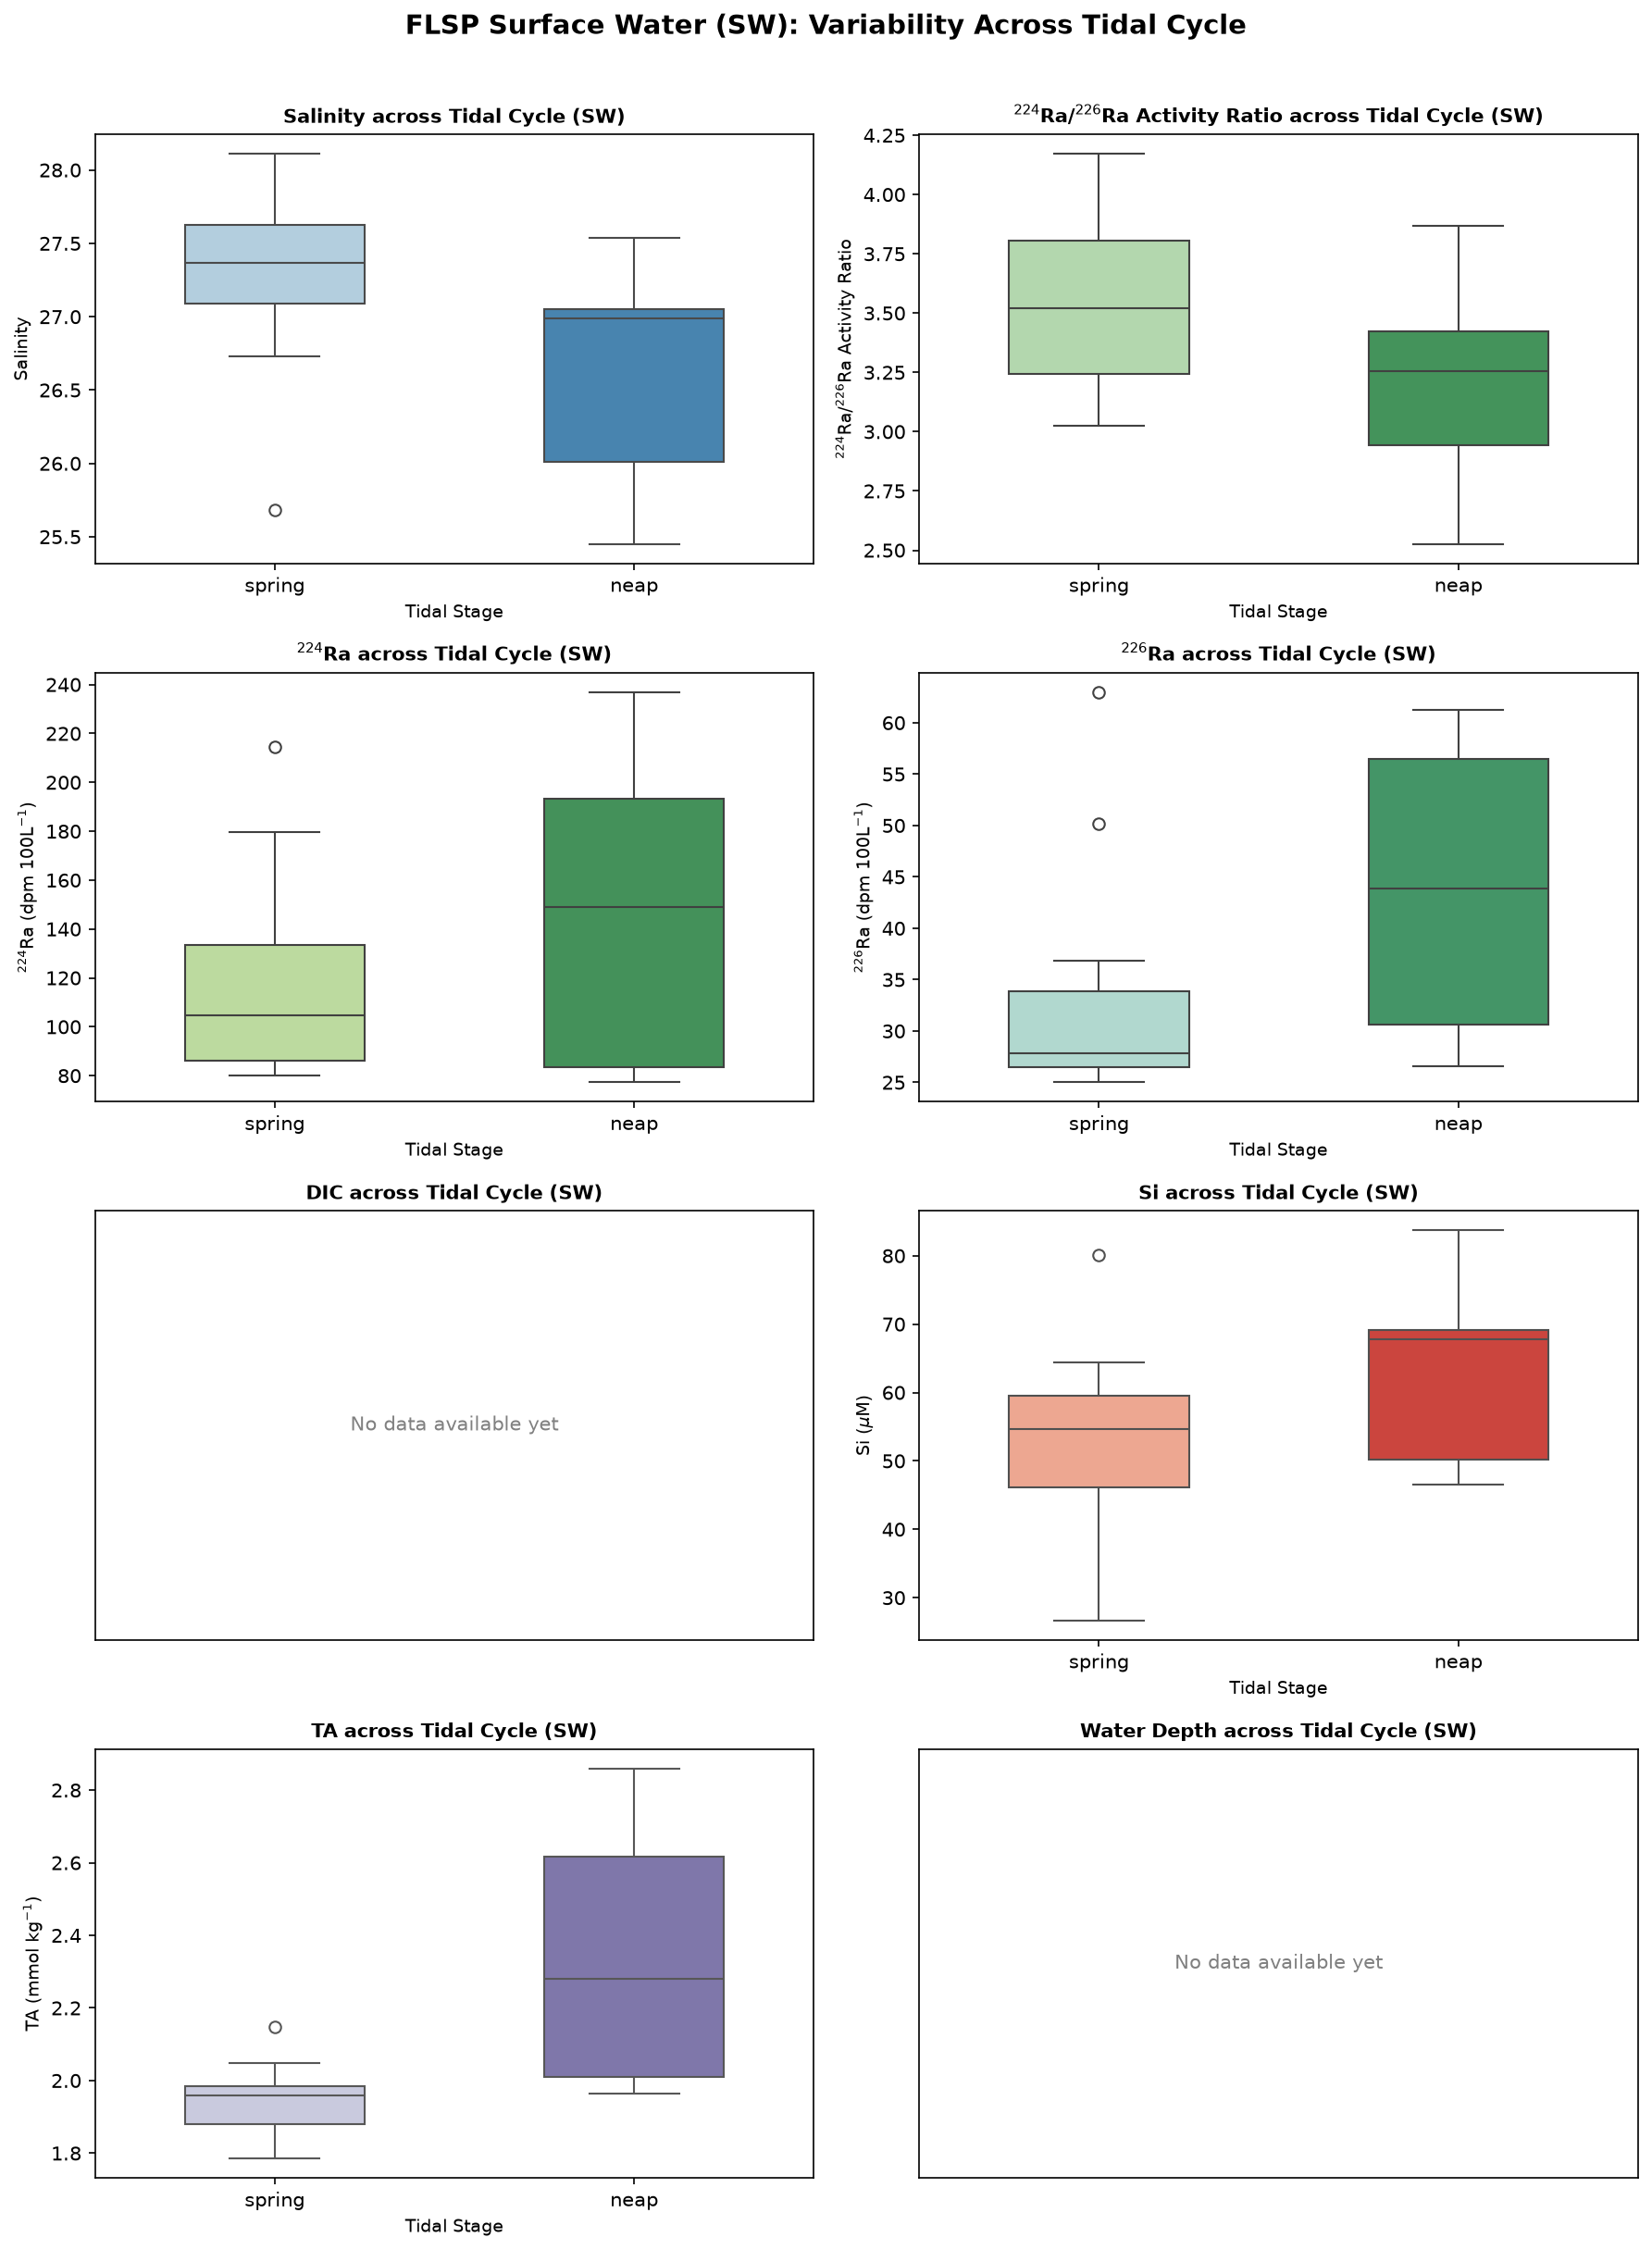

In [74]:
TIDE_COL = 'Tidal_Cycle'

# Filter FLSP to Surface Water (SW) only
sw_flsp = data_flsp[data_flsp['Sample_Type'] == 'SW'].copy()

# Panel specifications: (column_name, title, ylabel, palette)
flsp_panels = [
    ('Salinity',      'Salinity across Tidal Cycle (SW)',                           'Salinity',                           'Blues'),
    ('Ra224_226',     '$^{224}$Ra/$^{226}$Ra Activity Ratio across Tidal Cycle (SW)', '$^{224}$Ra/$^{226}$Ra Activity Ratio', 'Greens'),
    ('Ra224_dpm100L', '$^{224}$Ra across Tidal Cycle (SW)',                         r'$^{224}$Ra (dpm 100L$^{-1}$)',      'YlGn'),
    ('Ra226_dpm100L', '$^{226}$Ra across Tidal Cycle (SW)',                         r'$^{226}$Ra (dpm 100L$^{-1}$)',      'BuGn'),
    ('DIC_umolL',     'DIC across Tidal Cycle (SW)',                                r'DIC ($\mu$mol L$^{-1}$)',           'Oranges'),
    ('Si_uM',         'Si across Tidal Cycle (SW)',                                 r'Si ($\mu$M)',                       'Reds'),
    ('TA_mmolkg',     'TA across Tidal Cycle (SW)',                                 r'TA (mmol kg$^{-1}$)',               'Purples'),
    ('water_depth',   'Water Depth across Tidal Cycle (SW)',                        'Water Depth (m)',                    'PuBu'),
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16), dpi=150)
axes = axes.flatten()

for idx, (col, title, ylabel, pal) in enumerate(flsp_panels):
    ax = axes[idx]
    
    # Guard against missing columns or all-NaN columns
    if col in sw_flsp.columns and sw_flsp[col].notna().sum() > 0:
        sns.boxplot(
            data=sw_flsp, x=TIDE_COL, y=col,
            hue=TIDE_COL, palette=pal,
            legend=False, width=0.5, ax=ax
        )
        ax.set_xlabel('Tidal Stage', fontsize=9)
        ax.set_ylabel(ylabel, fontsize=9)
    else:
        ax.text(
            0.5, 0.5, 'No data available yet',
            ha='center', va='center', fontsize=10, color='gray', transform=ax.transAxes
        )
        ax.set_xticks([])
        ax.set_yticks([])
        
    ax.set_title(title, fontsize=10, fontweight='bold')

fig.suptitle('FLSP Surface Water (SW): Variability Across Tidal Cycle', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, "FLSP-surfacewater--tide-boxplots")
plt.show()

There doesn't appear to be any statistical differences between the spring and neap tidal cycle. Let's run some stats.

In [62]:
sw_flsp = data_flsp[data_flsp['Sample_Type'] == 'SW'].copy()

flsp_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'Si_uM', 'TA_mmolkg', 'water_depth'
]
valid_vars = [v for v in flsp_vars if v in sw_flsp.columns and sw_flsp[v].notna().sum() > 0]

tidal_results = []

for var in valid_vars:
    spring = sw_flsp[sw_flsp[TIDE_COL] == 'spring'][var].dropna()
    neap = sw_flsp[sw_flsp[TIDE_COL] == 'neap'][var].dropna()
    
    if len(spring) >= 2 and len(neap) >= 2:
        _, p_mwu = stats.mannwhitneyu(spring, neap, alternative='two-sided')
        _, p_lev = stats.levene(spring, neap, center='median')
        
        tidal_results.append({
            'Variable': var,
            'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})",
            'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})",
            'p_Median (MWU)': round(float(p_mwu), 4),
            'p_Variability (Levene)': round(float(p_lev), 4)
        })
    else:
        tidal_results.append({
            'Variable': var,
            'Spring Med (n)': f"{spring.median():.2f} ({len(spring)})" if len(spring) else "N/A (0)",
            'Neap Med (n)': f"{neap.median():.2f} ({len(neap)})" if len(neap) else "N/A (0)",
            'p_Median (MWU)': float('nan'),
            'p_Variability (Levene)': float('nan')
        })

flsp_tidal_df = pd.DataFrame(tidal_results)

has_p = flsp_tidal_df['p_Median (MWU)'].notna()
if has_p.any():
    p_vals = flsp_tidal_df.loc[has_p, 'p_Median (MWU)'].astype(float)
    flsp_tidal_df.loc[has_p, 'p_Median_adj'] = stats.false_discovery_control(
        p_vals, method='bh'
    ).round(4)
else:
    flsp_tidal_df['p_Median_adj'] = float('nan')

flsp_tidal_df['Spring vs Neap Diff?'] = flsp_tidal_df['p_Median_adj'].apply(
    lambda p: 'YES' if pd.notna(p) and p < 0.05 else ('Insufficient n' if pd.isna(p) else 'no')
)

flsp_tidal_df

,Variable,Spring Med (n),Neap Med (n),p_Median (MWU),p_Variability (Levene),p_Median_adj,Spring vs Neap Diff?
0,Salinity,27.37 (12),26.99 (9),0.0329,0.6392,0.0980,no
1,Ra224_226,3.52 (12),3.25 (9),0.0817,0.7083,0.0980,no
2,Ra224_dpm100L,104.60 (12),149.12 (9),0.5458,0.1386,0.5458,no
3,Ra226_dpm100L,27.85 (12),43.89 (9),0.0700,0.2451,0.0980,no
4,Si_uM,54.67 (12),67.74 (9),0.0817,0.8443,0.0980,no
5,TA_mmolkg,1.96 (12),2.28 (9),0.0025,0.0008,0.0150,YES


There is a statistical difference in TA between spring and neap tidal cycles, and that is the only variable to have a significant difference in spread.

In [63]:
flsp_vars = [
    'Salinity', 'Ra224_226', 'Ra224_dpm100L', 'Ra226_dpm100L',
    'DIC_umolL', 'Si_uM', 'TA_mmolkg', 'water_depth'
]
valid_vars = [v for v in flsp_vars if v in data_flsp.columns]

rows = {}

for stype in ['PW', 'GW']:
    df_s = data_flsp[data_flsp['Sample_Type'] == stype][valid_vars]
    if len(df_s) > 0:
        rows[(stype, 'n')] = df_s.count()
        rows[(stype, 'Median')] = df_s.median().round(2)
        rows[(stype, 'Min')] = df_s.min().round(2)
        rows[(stype, 'Max')] = df_s.max().round(2)
        rows[(stype, 'Mean')] = df_s.mean().round(2)
        rows[(stype, 'SD')] = df_s.std().round(2)

flsp_pw_gw_transposed = pd.DataFrame(rows).T
flsp_pw_gw_transposed.index.names = ['Sample_Type', 'Stat']
flsp_pw_gw_transposed

Salinity  Ra224_226  Ra224_dpm100L  Ra226_dpm100L  \
Sample_Type Stat                                                        
PW          n           9.00        0.0           9.00            0.0   
            Median     24.96        NaN         227.53            NaN   
            Min         5.26        NaN          32.09            NaN   
            Max        28.42        NaN         426.87            NaN   
            Mean       22.26        NaN         188.98            NaN   
            SD          7.21        NaN         124.30            NaN   
GW          n           1.00        0.0           1.00            0.0   
            Median      0.12        NaN          18.09            NaN   
            Min         0.12        NaN          18.09            NaN   
            Max         0.12        NaN          18.09            NaN   
            Mean        0.12        NaN          18.09            NaN   
            SD           NaN        NaN            NaN            NaN   

                    DIC_umolL   Si_uM  TA_mmolkg  
Sample_Type Stat                                  
PW          n             0.0    9.00       9.00  
            Median        NaN   79.49      10.10  
            Min           NaN   50.02       1.05  
            Max           NaN  139.82      14.71  
            Mean          NaN   90.41       9.50  
            SD            NaN   30.47       3.81  
GW          n             0.0    1.00       1.00  
            Median        NaN   22.35       0.15  
            Min           NaN   22.35       0.15  
            Max           NaN   22.35       0.15  
            Mean          NaN   22.35       0.15  
            SD            NaN     NaN        NaN

The focus for this report is to compare how these selected variables differ across seasons and tidal cycles. Once I nail these analyses, I will go on to compare these variables across sites to capture spatial variability. 

Also noting to myself to remember to fix the code and analyses as more data becomes available. Joe also suggested I make correlation matrices separating SW and PW and that I create time series plots for spring vs neap. This will be done in my EDA in the near future.